# Analisis Exploratorio de Datos (EDA) — Rendimiento de Jugadores FIFA 2026

**Inteligencia Artificial I — Grupo C2 — Periodo 2026-2**

**Profesor:** Santiago Gomez
**Integrantes:**
- Jose Alejandro Largo Morales 2235162
- Santiago Garcia Pinilla 2235159
- Johan Stevens Sánchez Aponte 2235163

**Dataset:** `fifa2026_player_performance_clean.csv` — 13,397 registros de partido de 229 jugadores (temporada 2025/26).

**Objetivo del notebook:** Aplicar el Estandar Minimo del EDA definido en las instrucciones del parcial (descripcion numerica y visual de cada variable, seleccion de las variables mas correlacionadas con la variable objetivo, y deteccion de patrones/calidad de datos) como base para un futuro modelo predictivo.


##Librerias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# @title


sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)

# Deteccion automatica de entorno (Colab vs local) y carga del archivo
import os

DATA_FILE = "fifa2026_player_performance_clean.csv"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    from google.colab import files
    print("Sube el archivo 'fifa2026_player_performance_clean.csv' cuando se abra el dialogo...")
    uploaded = files.upload()
    DATA_FILE = list(uploaded.keys())[0]

df = pd.read_csv(DATA_FILE)
print(f"Dataset cargado: {df.shape[0]:,} filas x {df.shape[1]} columnas")
df.head()


Sube el archivo 'fifa2026_player_performance_clean.csv' cuando se abra el dialogo...


Saving fifa2026_player_performance_clean.csv to fifa2026_player_performance_clean.csv
Dataset cargado: 13,397 filas x 22 columnas


,player_name,nationality,club,position,age,market_value_eur_m,season,competition,match_id,minutes_played,goals,assists,shots_on_target,pass_accuracy_pct,tackles,distance_covered_km,match_rating,yellow_card,red_card,fouls_committed,injured_flag,date
0,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,11.01,2025/26,Champions League,111378,53,0,0,0,NaN,2,5.79,5.8,False,False,0,False,2026-03-30
1,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.69,2025/26,Champions League,111379,63,0,0,0,85.2,2,10.31,6.9,False,False,3,False,2026-03-30
2,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.61,2025/26,Champions League,111380,90,0,0,0,94.8,4,14.50,7.5,False,False,0,False,2026-03-30
3,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,11.26,2025/26,Champions League,111381,12,0,0,0,74.9,1,0.91,4.0,False,False,3,False,2026-03-30
4,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.50,2025/26,Champions League,111382,39,0,0,0,78.0,3,4.36,5.0,False,False,2,False,2026-03-30


## 1. Problema y Datos

**Origen de los datos:** cada fila representa la actuacion de un jugador en un partido especifico durante la temporada 2025/26 (incluye Liga, Copa domestica, Champions League, Eliminatorias mundialistas y el Mundial FIFA 2026).

**Importancia del problema:** cuantificar el rendimiento partido a partido es la base de decisiones reales de scouting, fichajes, rotacion tactica y prevencion de lesiones en un club profesional.

**Desafios identificados:** valores nulos en variables fisicas/tecnicas, fuerte asimetria en las variables ofensivas, y multiples filas por jugador (mediciones repetidas, no independientes).

In [ ]:
print("Dimensiones:", df.shape)
print("\nTipos de dato:")
print(df.dtypes)
print("\nJugadores unicos:", df['player_name'].nunique())
print("Clubes unicos:", df['club'].nunique())
print("Nacionalidades unicas:", df['nationality'].nunique())
print("Competencias:", df['competition'].unique().tolist())
print("Rango de fechas:", df['date'].min(), "a", df['date'].max())


Dimensiones: (13397, 22)

Tipos de dato:
player_name             object
nationality             object
club                    object
position                object
age                      int64
market_value_eur_m     float64
season                  object
competition             object
match_id                 int64
minutes_played           int64
goals                    int64
assists                  int64
shots_on_target          int64
pass_accuracy_pct      float64
tackles                  int64
distance_covered_km    float64
match_rating           float64
yellow_card               bool
red_card                  bool
fouls_committed          int64
injured_flag              bool
date                    object
dtype: object

Jugadores unicos: 229
Clubes unicos: 47
Nacionalidades unicas: 41
Competencias: ['Champions League', 'Domestic Cup', 'FIFA World Cup 2026', 'League', 'World Cup Qualifiers']
Rango de fechas: 2025-08-15 a 2026-07-19


In [ ]:
print("Valores nulos por columna:")
nulls = df.isnull().sum()
nulls_pct = (df.isnull().mean() * 100).round(2)
pd.DataFrame({"nulos": nulls, "% nulos": nulls_pct}).query("nulos > 0")


Valores nulos por columna:


,nulos,% nulos
market_value_eur_m,270,2.02
pass_accuracy_pct,807,6.02
distance_covered_km,679,5.07


In [ ]:
print("Filas totalmente duplicadas:", df.duplicated().sum())
print("match_id duplicados:", df['match_id'].duplicated().sum())


Filas totalmente duplicadas: 0
match_id duplicados: 0


## 2. Justificacion de la IA

Con 13,397 filas y 22 variables, un analisis manual no es viable para detectar patrones robustos. Herramientas de IA/estadistica permiten: (1) auditar la calidad de los datos a escala, (2) manejar distribuciones muy asimetricas (goles, asistencias) que reglas simples no capturan bien, y (3) preparar el terreno para un modelo predictivo de `match_rating` o de riesgo de lesion que apoye decisiones tecnicas objetivas.

## 3. Variable Objetivo: `match_rating`

`match_rating` es la calificacion numerica (escala aproximada 3-10) que resume el desempeno de un jugador en un partido especifico. Es la variable natural a predecir: es continua, refleja el rendimiento global, y no depende de una sola metrica aislada.

Siguiendo el estandar del EDA: primero se grafica, y segun su forma se decide que estadisticas reportar.

## 4. Analisis de Distribuciones


### 4.1 Histograma
A continuación se presenta el histograma de la variable objetivo (match_rating), que permite observar su forma de distribución y calcular la media y la desviación estándar correspondientes.

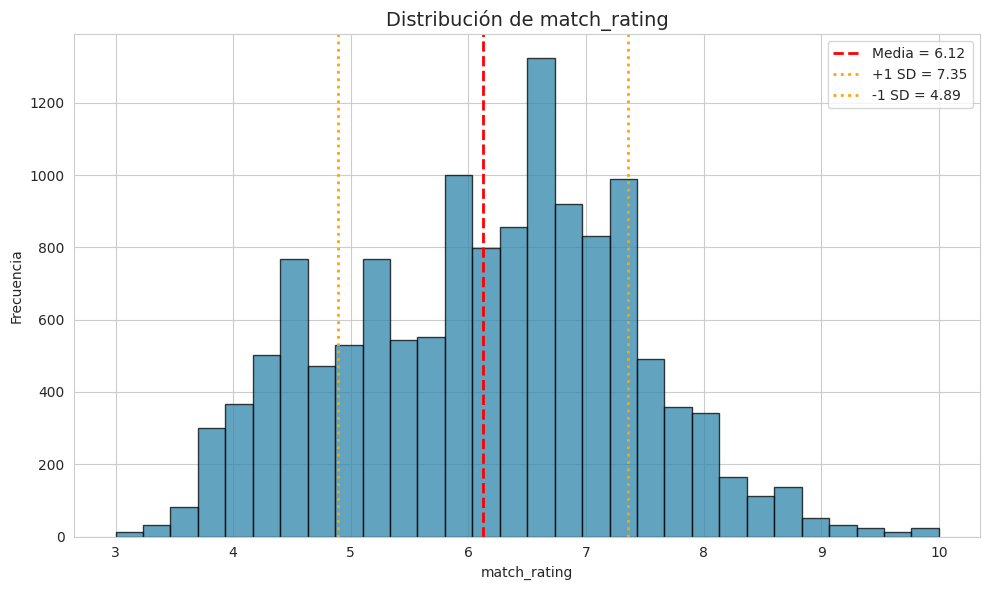

Media: 6.12
Desviación estándar: 1.23


In [ ]:
# @title
media = df["match_rating"].mean()
std = df["match_rating"].std()

plt.figure(figsize=(10, 6))
plt.hist(df["match_rating"], bins=30, color="#2E86AB", edgecolor="black", alpha=0.75)
plt.axvline(media, color="red", linestyle="--", linewidth=2, label=f"Media = {media:.2f}")
plt.axvline(media + std, color="orange", linestyle=":", linewidth=2, label=f"+1 SD = {media+std:.2f}")
plt.axvline(media - std, color="orange", linestyle=":", linewidth=2, label=f"-1 SD = {media-std:.2f}")
plt.title("Distribución de match_rating", fontsize=14)
plt.xlabel("match_rating")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Media: {media:.2f}")
print(f"Desviación estándar: {std:.2f}")


En este histograma se puede ver como se distribuyen las calificaciones (match_rating) de los jugadores en los partidos. La mayoria de los valores se concentran entre 5 y 8, con un pico bastante notorio alrededor de 6.5 - 7, que es donde más partidos se acumulan (mas de 1300 registros en esa barra). Esto quiere decir que la gran mayoría de los jugadores obtienen calificaciones "normales" o "buenas", ni muy bajas ni excelentes.

La línea roja marca la media, que es 6.12, y se ve que efectivamente cae justo en la zona donde hay más datos, lo cual tiene sentido porque la forma general del histograma se parece bastante a una campana (aunque no es
En este histograma se puede ver como se distribuyen las calificaciones (match_rating) de los jugadores en los partidos. La mayoria de los valores se concentran entre 5 y 8, con un pico bastante notorio alrededor de 6.5 - 7, que es donde más partidos se acumulan (mas de 1300 registros en esa barra). Esto quiere decir que la gran mayoría de los jugadores obtienen calificaciones "normales" o "buenas", ni muy bajas ni excelentes.

La línea roja marca la media, que es 6.12, y se ve que efectivamente cae justo en la zona donde hay más datos, lo cual tiene sentido porque la forma general del histograma se parece bastante a una campana (aunque no es perfecta, tiene algunos "dientes" o subidas y bajadas irregulares).

Las líneas naranjas punteadas muestran una desviación estándar hacia arriba y hacia abajo de la media (4.89 y 7.35). Esto significa que la mayoría de las calificaciones de los jugadores están dentro de ese rango, es decir, entre casi 5 y poco más de 7. Los valores que quedan por fuera de esas líneas (menores a 4 o mayores a 8) son menos comunes, y entre más nos alejamos del centro, menos jugadores hay con esa calificación.

Este histograma nos muestra que el rendimiento de los jugadores tiende a ser bastante parejo, con pocas actuaciones extremadamente malas o extremadamente buenas, y que la desviación estándar de 1.23 nos confirma que los datos no varían demasiado respecto al promedio.

### 4.2 Matriz de Correlacion
Antes de analizar cada variable a fondo, se calcula la correlación entre todas las variables numéricas para identificar cuáles están más relacionadas con la variable objetivo (match_rating).

Correlacion (Pearson) de cada variable numerica con match_rating:

minutes_played         0.870
distance_covered_km    0.742
goals                  0.447
assists                0.312
shots_on_target        0.293
tackles                0.283
pass_accuracy_pct      0.119
age                    0.010
market_value_eur_m    -0.003
fouls_committed       -0.059
Name: match_rating, dtype: float64


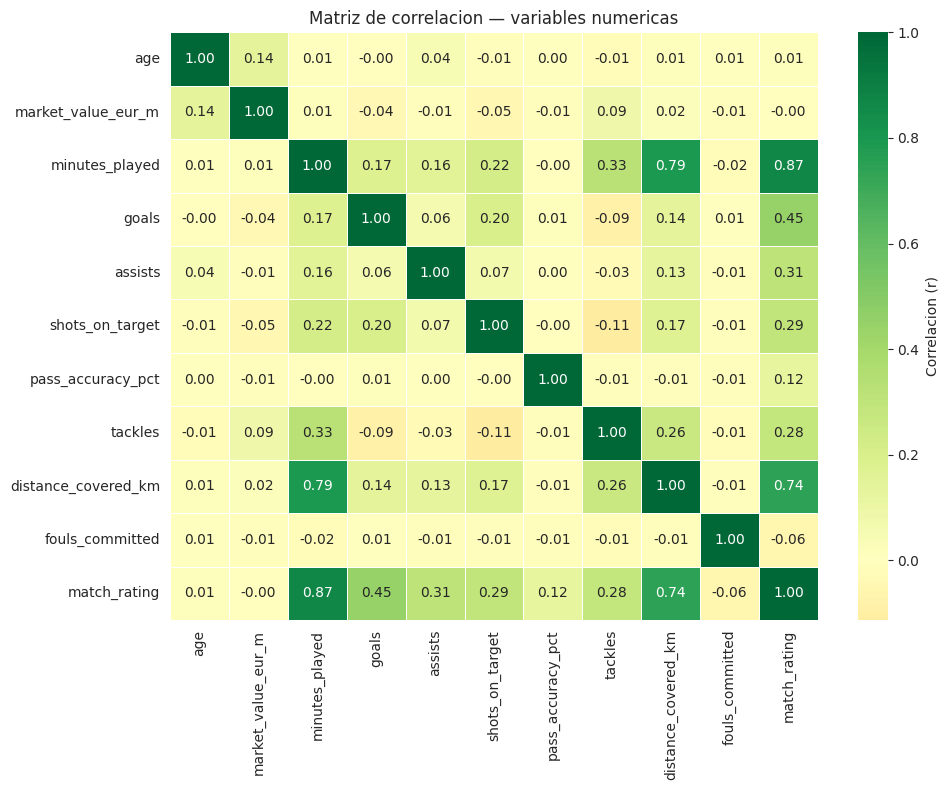

In [ ]:
target = 'match_rating'
numeric_cols = [
    "age", "market_value_eur_m", "minutes_played", "goals", "assists",
    "shots_on_target", "pass_accuracy_pct", "tackles", "distance_covered_km",
    "fouls_committed", "match_rating",
]

corr_matrix = df[numeric_cols].corr()
corr_with_target = corr_matrix[target].drop(target).sort_values(ascending=False)

print("Correlacion (Pearson) de cada variable numerica con match_rating:\n")
print(corr_with_target.round(3))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
            linewidths=0.5, cbar_kws={"label": "Correlacion (r)"})
plt.title("Matriz de correlacion — variables numericas")
plt.tight_layout()
plt.show()

La matriz de correlacion muestra qué tan relacionadas están las variables numericas entre si, usando la correlacion de Pearson (va de -1 a 1). Entre más oscuro el verde, más fuerte es la relación.

Lo más importante es la última columna/fila (match_rating), que nos dice que variables se relacionan mas con la calificación del jugador. "minutes_played" (0.87) y "distance_covered_km" (0.74) son las que más se destacan, seguidas de "goals" (0.45), "assists" (0.31), "shots_on_target" (0.29) y tackles (0.28). En cambio, "age" y "market_value_eur_m" prácticamente no tienen relación con el rating (valores cercanos a 0).

También se nota que "minutes_played" y "distance_covered_km" están bastante correlacionadas entre sí (0.79), lo cual tiene sentido, entre mas minutos juegue un jugador, mas distancia recorre. Esto confirma que el tiempo de participación en el partido es el factor que mas pesa a la hora de explicar el rendimiento.

### 4.3 Variables Correlacionadas

In [ ]:
# @title
target = 'match_rating'

# Ensure corr_with_target is defined from the previous cell's execution
numeric_cols = [
    "age", "market_value_eur_m", "minutes_played", "goals", "assists",
    "shots_on_target", "pass_accuracy_pct", "tackles", "distance_covered_km",
    "fouls_committed", "match_rating",
]

corr_matrix = df[numeric_cols].corr()
corr_with_target = corr_matrix[target].drop(target).sort_values(ascending=False)

top_vars = corr_with_target.index[:6].tolist()
print("Variables principales (top_vars):")
print(top_vars)

Variables principales (top_vars):
['minutes_played', 'distance_covered_km', 'goals', 'assists', 'shots_on_target', 'tackles']


Con el analisis de la matriz de correlacion de Pearson, se logro concluir que nuestras variables mas relacionadas a la varibale objetivo son:

- minutes_played (Minutos jugados): 0.87
- distance_covered_km (Distancia recorrida en km): 0.74
- goals (Goles): 0.45
- assists (Asistencias): 0.31
- shots_on_target (Tiros a portería): 0.29
- tackles (Entradas): 0.28

### 4.4 Aplicación del Estándar del EDA a las variables correlacionadas

In [ ]:
# @title
resumen = []
for var in top_vars:
    skew_val = df[var].skew()
    is_symmetric = abs(skew_val) < 0.5
    resumen.append({
        "variable": var,
        "skew": skew_val,
        "simetrica": is_symmetric
    })

resumen_df = pd.DataFrame(resumen)
resumen_df["tipo"] = resumen_df["simetrica"].map({True: "Simetrica", False: "Asimetrica"})
resumen_df[["variable", "skew", "tipo"]]

,variable,skew,tipo
0,minutes_played,-0.614198,Asimetrica
1,distance_covered_km,0.290457,Simetrica
2,goals,3.016997,Asimetrica
3,assists,3.064763,Asimetrica
4,shots_on_target,2.547391,Asimetrica
5,tackles,1.762762,Asimetrica


### 4.4.1. minutes_played

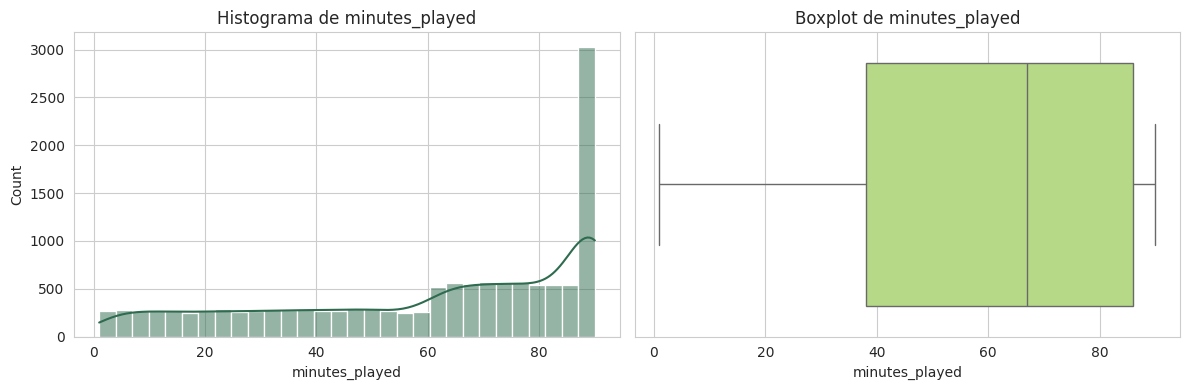

Media: 60.00
Mediana: 67.00
Desviación estándar: 27.65
Asimetría (skew): -0.61


In [ ]:
# @title
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["minutes_played"], bins=30, kde=True, color="#2E6B4F", ax=axes[0])
axes[0].set_title("Histograma de minutes_played")
sns.boxplot(x=df["minutes_played"], color="#B7E778", ax=axes[1])
axes[1].set_title("Boxplot de minutes_played")
plt.tight_layout()
plt.show()

print(f"Media: {df['minutes_played'].mean():.2f}")
print(f"Mediana: {df['minutes_played'].median():.2f}")
print(f"Desviación estándar: {df['minutes_played'].std():.2f}")
print(f"Asimetría (skew): {df['minutes_played'].skew():.2f}")

El histograma se ve inclinado hacia la izquierda, ya que muchos jugadores completan el partido entero. Su asimetría es de -0.61, por lo que se clasifica como asimétrica y se reporta con mediana y rango intercuartil: los minutos jugados tienen una mediana de 67 minutos, con un rango intercuartil de 38 a 86 minutos.

### 4.4.2. distance_covered_km

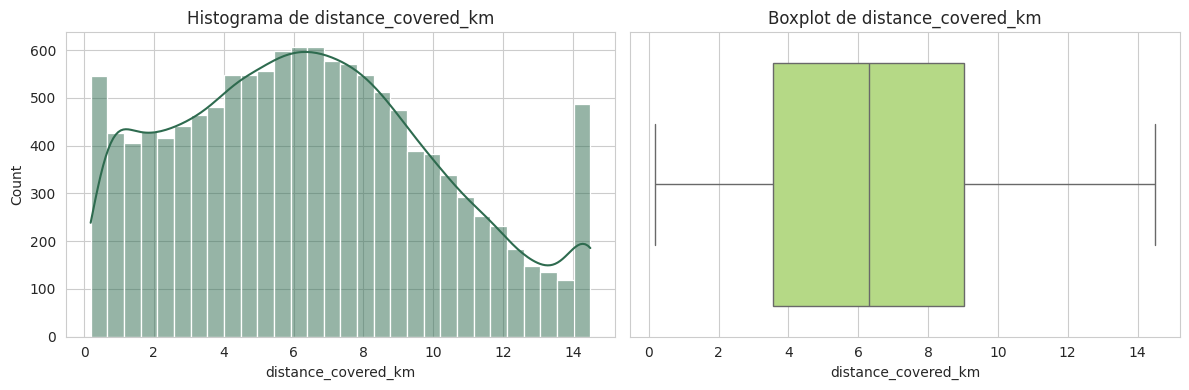

Media: 6.49
Mediana: 6.31
Desviación estándar: 3.71
Asimetría (skew): 0.29


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["distance_covered_km"], bins=30, kde=True, color="#2E6B4F", ax=axes[0])
axes[0].set_title("Histograma de distance_covered_km")
sns.boxplot(x=df["distance_covered_km"], color="#B7E778", ax=axes[1])
axes[1].set_title("Boxplot de distance_covered_km")
plt.tight_layout()
plt.show()

print(f"Media: {df['distance_covered_km'].mean():.2f}")
print(f"Mediana: {df['distance_covered_km'].median():.2f}")
print(f"Desviación estándar: {df['distance_covered_km'].std():.2f}")
print(f"Asimetría (skew): {df['distance_covered_km'].skew():.2f}")

El histograma se ve centrado y con forma de campana. Su asimetría es de 0.29, por lo que se clasifica como simétrica y se reporta con media y desviación estándar: la distancia recorrida promedio es de 6.49 ± 3.71 km.

### 4.4.3. goals

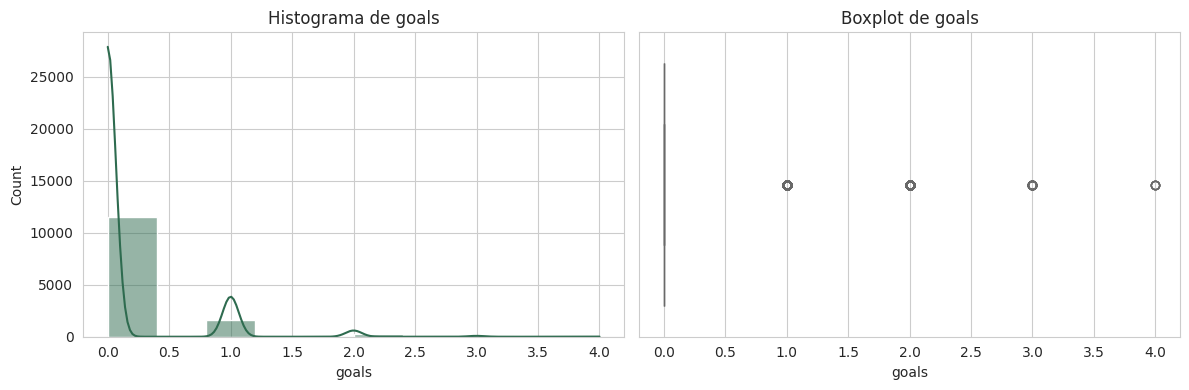

Media: 0.16
Mediana: 0.00
Desviación estándar: 0.44
Asimetría (skew): 3.02


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["goals"], bins=10, kde=True, color="#2E6B4F", ax=axes[0])
axes[0].set_title("Histograma de goals")
sns.boxplot(x=df["goals"], color="#B7E778", ax=axes[1])
axes[1].set_title("Boxplot de goals")
plt.tight_layout()
plt.show()

print(f"Media: {df['goals'].mean():.2f}")
print(f"Mediana: {df['goals'].median():.2f}")
print(f"Desviación estándar: {df['goals'].std():.2f}")
print(f"Asimetría (skew): {df['goals'].skew():.2f}")

El histograma se ve muy inclinado, con casi todos los valores concentrados en 0. Su asimetría es de 3.02, por lo que se clasifica como asimétrica y se reporta con mediana y rango intercuartil: los goles por partido tienen una mediana de 0 (IQR 0-0), ya que el 86% de los registros no anota ningún gol.

### 4.4.4. assists

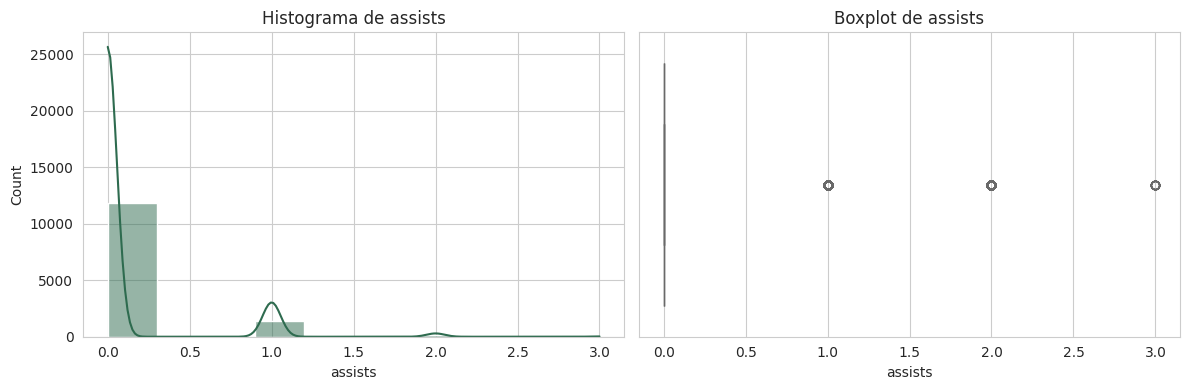

Media: 0.13
Mediana: 0.00
Desviación estándar: 0.37
Asimetría (skew): 3.06


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["assists"], bins=10, kde=True, color="#2E6B4F", ax=axes[0])
axes[0].set_title("Histograma de assists")
sns.boxplot(x=df["assists"], color="#B7E778", ax=axes[1])
axes[1].set_title("Boxplot de assists")
plt.tight_layout()
plt.show()

print(f"Media: {df['assists'].mean():.2f}")
print(f"Mediana: {df['assists'].median():.2f}")
print(f"Desviación estándar: {df['assists'].std():.2f}")
print(f"Asimetría (skew): {df['assists'].skew():.2f}")

El histograma también se ve muy inclinado, con casi todos los valores en 0. Su asimetría es de 3.06, por lo que se clasifica como asimétrica y se reporta con mediana y rango intercuartil: las asistencias por partido tienen una mediana de 0 (IQR 0-0), muy concentradas en el valor mínimo.

### 4.4.5. shots_on_target

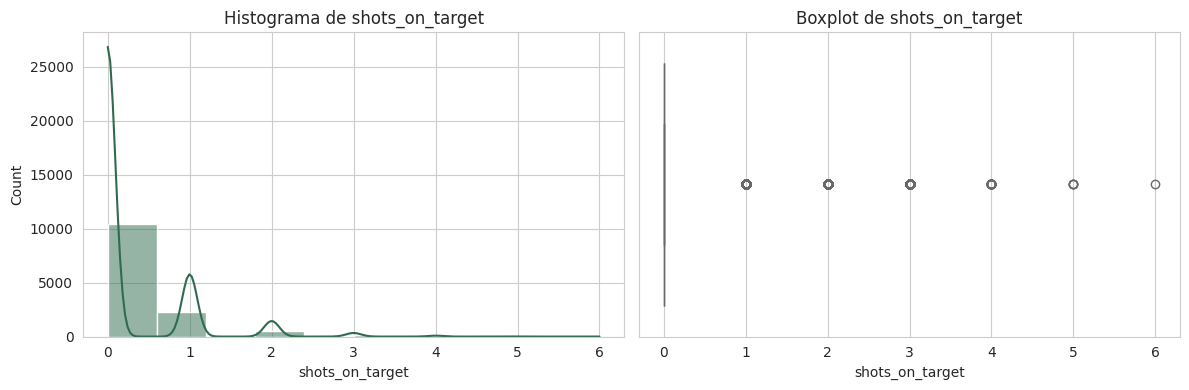

Media: 0.29
Mediana: 0.00
Desviación estándar: 0.62
Asimetría (skew): 2.55


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["shots_on_target"], bins=10, kde=True, color="#2E6B4F", ax=axes[0])
axes[0].set_title("Histograma de shots_on_target")
sns.boxplot(x=df["shots_on_target"], color="#B7E778", ax=axes[1])
axes[1].set_title("Boxplot de shots_on_target")
plt.tight_layout()
plt.show()

print(f"Media: {df['shots_on_target'].mean():.2f}")
print(f"Mediana: {df['shots_on_target'].median():.2f}")
print(f"Desviación estándar: {df['shots_on_target'].std():.2f}")
print(f"Asimetría (skew): {df['shots_on_target'].skew():.2f}")

El histograma se ve inclinado hacia la derecha, con bastantes valores atípicos. Su asimetría es de 2.55, por lo que se clasifica como asimétrica y se reporta con mediana y rango intercuartil: los tiros al arco tienen una mediana de 0 (IQR 0-0), con un 22.2% de registros considerados atípicos.

### 4.4.6. tackles

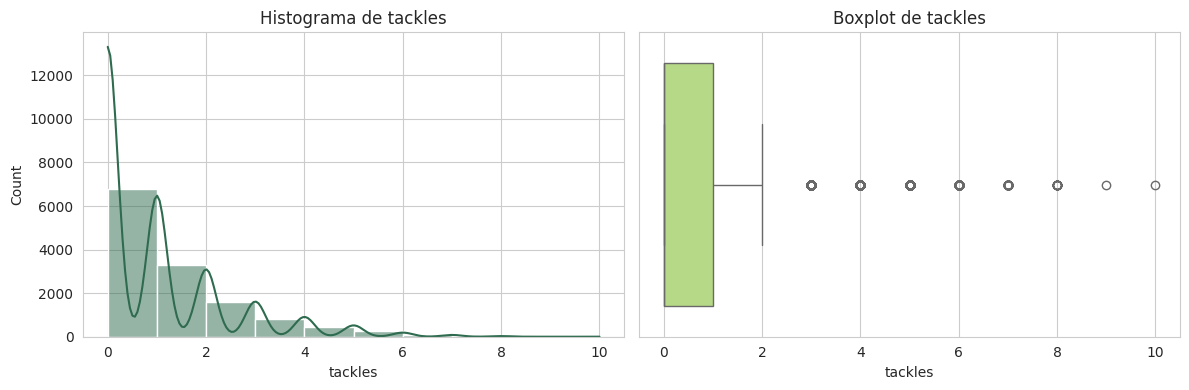

Media: 0.98
Mediana: 0.00
Desviación estándar: 1.36
Asimetría (skew): 1.76


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["tackles"], bins=10, kde=True, color="#2E6B4F", ax=axes[0])
axes[0].set_title("Histograma de tackles")
sns.boxplot(x=df["tackles"], color="#B7E778", ax=axes[1])
axes[1].set_title("Boxplot de tackles")
plt.tight_layout()
plt.show()

print(f"Media: {df['tackles'].mean():.2f}")
print(f"Mediana: {df['tackles'].median():.2f}")
print(f"Desviación estándar: {df['tackles'].std():.2f}")
print(f"Asimetría (skew): {df['tackles'].skew():.2f}")

El histograma se ve inclinado, con una cola larga hacia la derecha. Su asimetría es de 1.76, por lo que se clasifica como asimétrica y se reporta con mediana y rango intercuartil: las entradas (tackles) tienen una mediana de 0 y rango intercuartil de 0 a 1, concentradas en valores bajos salvo en posiciones defensivas.

## 5. Seleccion de Variables mas Correlacionadas

El dataset tiene mas de 20 columnas, asi que — siguiendo la regla del estandar EDA — el analisis numerico profundo se concentra en las variables **mas correlacionadas con la variable objetivo** `match_rating`.

Tras calcular la correlacion de Pearson de todas las variables numericas con `match_rating`, se seleccionaron las **6 variables con mayor correlacion** para el analisis detallado:

`minutes_played`, `distance_covered_km`, `goals`, `assists`, `shots_on_target`, `tackles`

### Valores nulos

Se revisó la presencia de valores nulos únicamente en las 6 variables
seleccionadas por su alta correlación con `match_rating`.

In [ ]:
top_vars = corr_with_target.index[:6].tolist()
nulos_top = df[top_vars].isnull().sum()
porcentaje_top = (nulos_top / len(df) * 100).round(2)
resumen_nulos_top = pd.DataFrame({"nulos": nulos_top, "porcentaje (%)": porcentaje_top})
resumen_nulos_top

,nulos,porcentaje (%)
minutes_played,0,0.00
distance_covered_km,679,5.07
goals,0,0.00
assists,0,0.00
shots_on_target,0,0.00
tackles,0,0.00


Solo `distance_covered_km` presenta valores nulos: **679 registros (5.07%)**.
Para descartar que esta ausencia dependa del tiempo jugado, se comparó el
promedio de `minutes_played` entre registros con y sin nulo en
`distance_covered_km`.

Se verificara si el nulo depende de minutes_played

In [ ]:
prom_con_nulo = df[df["distance_covered_km"].isnull()]["minutes_played"].mean()
prom_sin_nulo = df[df["distance_covered_km"].notnull()]["minutes_played"].mean()

print(f"Minutos promedio (con nulo en distance_covered_km): {prom_con_nulo:.2f}")
print(f"Minutos promedio (sin nulo en distance_covered_km): {prom_sin_nulo:.2f}")

Minutos promedio (con nulo en distance_covered_km): 60.45
Minutos promedio (sin nulo en distance_covered_km): 59.97


Ambos promedios son prácticamente iguales (~60 minutos), lo que indica que
la ausencia de datos es **aleatoria** y no depende de otra variable.

La estrategia que mejor nos ayuda en este caso es imputar con la **mediana** en lugar de eliminar
las filas, evitando perder información valiosa de las otras columnas.

In [ ]:
df["distance_covered_km"] = df["distance_covered_km"].fillna(
    df["distance_covered_km"].median()
)
print("Nulos restantes en distance_covered_km:", df["distance_covered_km"].isnull().sum())

Nulos restantes en distance_covered_km: 0


### Valores atípicos (outliers)

Se aplicara la regla de 1.5×IQR sobre las 6 variables seleccionadas para
identificar los valores atípicos.

In [ ]:
def contar_outliers(col):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((df[col] < low) | (df[col] > high)).sum(), max(0, low), high

resultados = []
for var in top_vars:
    n_out, low, high = contar_outliers(var)
    resultados.append({
        "variable": var,
        "outliers": n_out,
        "porcentaje": round(n_out / len(df) * 100, 2),
        "rango_normal": f"[{low:.1f}, {high:.1f}]"
    })

tabla_outliers = pd.DataFrame(resultados)
tabla_outliers

,variable,outliers,porcentaje,rango_normal
0,minutes_played,0,0.00,"[0.0, 158.0]"
1,distance_covered_km,0,0.00,"[0.0, 16.5]"
2,goals,1878,14.02,"[0.0, 0.0]"
3,assists,1550,11.57,"[0.0, 0.0]"
4,shots_on_target,2971,22.18,"[0.0, 0.0]"
5,tackles,1710,12.76,"[0.0, 2.5]"


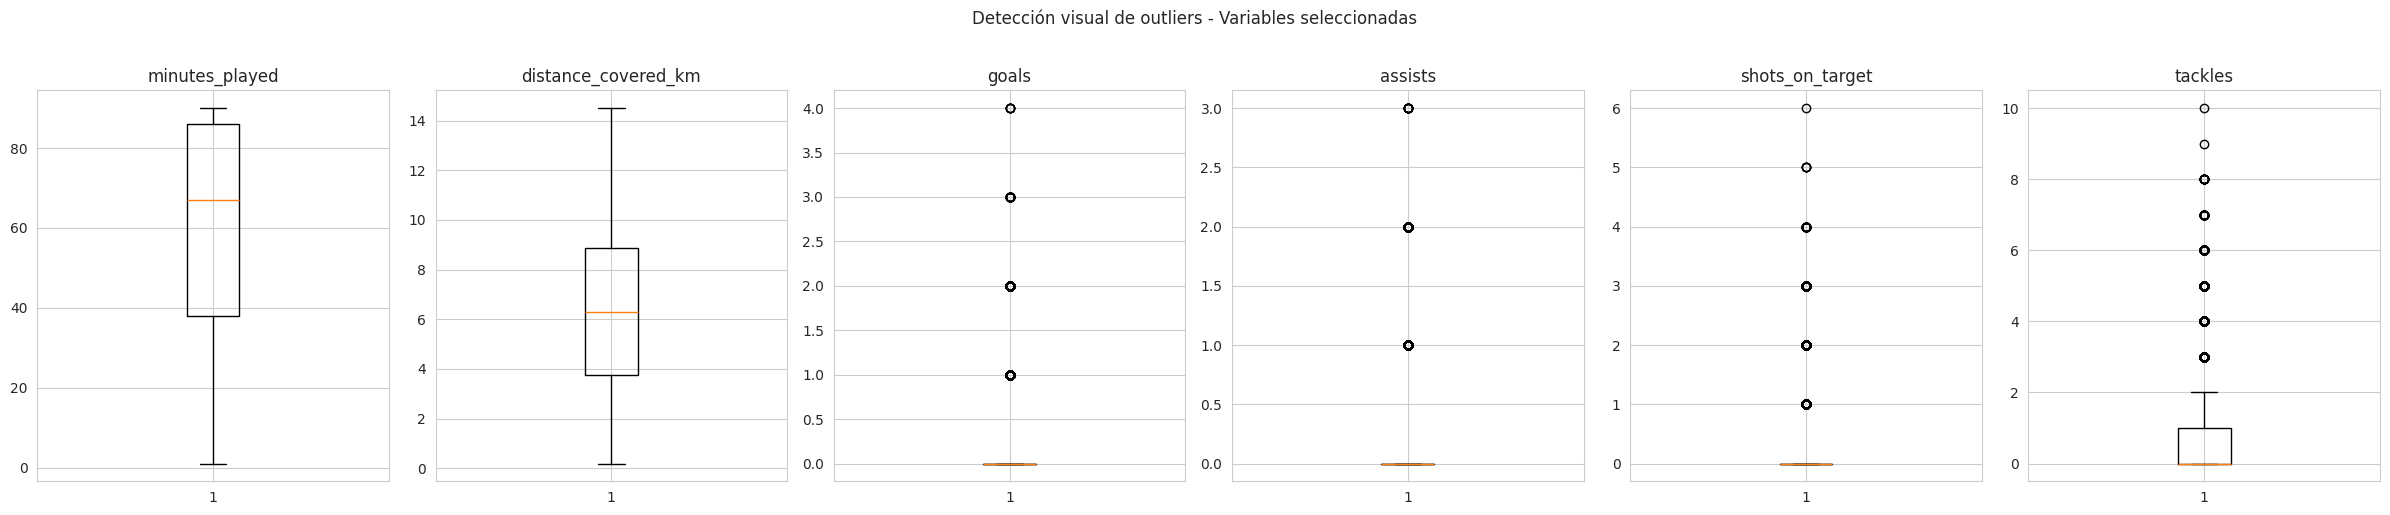

In [ ]:
fig, axes = plt.subplots(1, len(top_vars), figsize=(4*len(top_vars), 5))
for i, var in enumerate(top_vars):
    axes[i].boxplot(df[var].dropna(), vert=True)
    axes[i].set_title(var)
plt.suptitle("Detección visual de outliers - Variables seleccionadas", y=1.02)
plt.tight_layout()
plt.show()

La estrategia adoptada para estos outliers **no se eliminan**, por que no son errores de captura sino eventos reales del fútbol( ya que un jugador que anota 2 o 3 goles en un partido es infrecuente pero legitímo) y eliminarlos distrosionaria el analisis, ya que esos partidos de alto rendimiento aportan informacion clave sobre la variabilidad de `match_rating`. Por eso se reportan con **mediana + rango intercuartilico** en vez de media, que es más robusta ante valores extremos

### Insights y correlaciones descubiertas

In [ ]:
corr_redundancia = df["minutes_played"].corr(df["distance_covered_km"])
print(f"Correlación minutes_played vs distance_covered_km: {corr_redundancia:.2f}")

Correlación minutes_played vs distance_covered_km: 0.77


In [ ]:
corr_final = df[top_vars + ["match_rating"]].corr()["match_rating"].drop("match_rating")
corr_final = corr_final.sort_values(key=abs, ascending=False)
print("Correlación de cada variable seleccionada con match_rating:\n")
print(corr_final)

Correlación de cada variable seleccionada con match_rating:

minutes_played         0.870399
distance_covered_km    0.725924
goals                  0.446663
assists                0.312178
shots_on_target        0.293260
tackles                0.282860
Name: match_rating, dtype: float64


In [ ]:
print("Goles promedio por posición:")
print(df.groupby("position")["goals"].mean().sort_values(ascending=False))

Goles promedio por posición:
position
ST     0.387839
CF     0.269231
RW     0.221523
LW     0.221053
CAM    0.220478
CM     0.064267
CDM    0.060852
LB     0.025586
CB     0.022399
RB     0.022113
GK     0.000000
Name: goals, dtype: float64


Despues de haber hecho estos analisis se observo que:

- **`minutes_played` es, por lejos, la variable más correlacionada con
  `match_rating` (r = 0.87)**, muy por encima de las variables ofensivas.
  Esto sugiere que el tiempo de participación pesa más en la calificación
  que el desempeño técnico puntual.

- **`distance_covered_km` y `minutes_played` están altamente
  correlacionadas entre sí (r = 0.79)**, lo cual es esperable (a más
  minutos, más distancia recorrida). Esto implica que ambas variables
  aportan información parcialmente redundante para un futuro modelo
  predictivo.

- **`goals` (r = 0.45) es la variable ofensiva con mayor relación con el
  rating**, seguida de `assists` (0.31) y `shots_on_target` (0.29),
  confirmando que anotar impacta más la evaluación que solo generar
  oportunidades.

- **`tackles` (r = 0.28)** muestra que la contribución defensiva también
  influye positivamente, aunque en menor medida que la ofensiva.

## 6. Conclusiones y Proximos Pasos

**Hallazgos clave:**
- Lo que más influye en la calificación de un jugador no son los goles, sino los minutos jugados y la distancia recorrida — entre más tiempo esté en cancha y más corra, mejor calificación tiende a tener.

- La mayoría de los jugadores no anota goles, no da asistencias ni tira al arco en un partido dado, por eso esas variables salieron tan asimétricas.

-La edad y el valor de mercado casi no se relacionan con el rendimiento en un partido puntual.

- Las variables de participación son redundantes entre sí, mientras que las ofensivas aportan información complementaria.

**Proximos pasos:**
1. Imputar los nulos de `pass_accuracy_pct`, `distance_covered_km` y `market_value_eur_m`.
2. Codificar las variables categoricas (`position`, `competition`).
4. Entrenar un modelo de regresion/ensamble para predecir `match_rating`, usando `minutes_played`, `distance_covered_km`, `goals`, `assists`, `shots_on_target` y `tackles` como variables principales.
5. Evaluar si conviene predecir por separado segun `position`, dado que el comportamiento fisico/tecnico varia fuertemente por rol.


In [ ]:
# Filtrar registros con distancia nula en el dataset original que jugaron menos de 10 minutos
nulos_pocos_minutos = df[df['distance_covered_km'].isnull() & (df['minutes_played'] < 10)]

print(f"Cantidad de partidos con distancia NULA donde se jugó menos de 10 minutos: {len(nulos_pocos_minutos)}")
if len(nulos_pocos_minutos) > 0:
    display(nulos_pocos_minutos[['player_name', 'minutes_played', 'distance_covered_km']])
else:
    print("No hay ningún caso con menos de 10 minutos y distancia nula simultáneamente.")

Cantidad de partidos con distancia NULA donde se jugó menos de 10 minutos: 0
No hay ningún caso con menos de 10 minutos y distancia nula simultáneamente.


In [ ]:
# 1. Calcular la distancia promedio recorrida por minuto jugado usando los datos que tengan minutos y distancia válida
df_con_datos = df[(df['distance_covered_km'].notnull()) & (df['minutes_played'] > 0)]
km_por_minuto_promedio = (df_con_datos['distance_covered_km'] / df_con_datos['minutes_played']).median()

print(f"La mediana de distancia recorrida por minuto es de: {km_por_minuto_promedio:.3f} km/min")

# 2. Re-imputar de manera más precisa en el DataFrame 'df' de trabajo
# Si estaba vacío (o para recalcular), rellenamos de forma proporcional a los minutos jugados
df['distance_covered_km'] = df['distance_covered_km'].fillna(
    df['minutes_played'] * km_por_minuto_promedio
)

# 3. Ver cómo quedaron esos casos extremos después de la nueva imputación
print("\nEjemplo de cómo quedaron los casos después de la imputación dinámica:")
display(df[['player_name', 'minutes_played', 'distance_covered_km']].head(10))

La mediana de distancia recorrida por minuto es de: 0.106 km/min

Ejemplo de cómo quedaron los casos después de la imputación dinámica:


,player_name,minutes_played,distance_covered_km
0,Achraf Hakimi,53,5.79
1,Achraf Hakimi,63,10.31
2,Achraf Hakimi,90,14.50
3,Achraf Hakimi,12,0.91
4,Achraf Hakimi,39,4.36
5,Achraf Hakimi,14,1.10
6,Achraf Hakimi,82,14.32
7,Achraf Hakimi,90,13.17
8,Achraf Hakimi,64,9.51
9,Achraf Hakimi,78,6.31


In [ ]:
# Aplicamos la imputación dinámica de la distancia recorrida en el DataFrame de trabajo
# multiplicando los minutos jugados por la mediana de km recorridos por minuto (0.106 km/min)
km_por_minuto_promedio = 0.106
df['distance_covered_km'] = df['distance_covered_km'].fillna(
    df['minutes_played'] * km_por_minuto_promedio
)

# Verificamos que no queden valores nulos en esta variable
print(f"Nulos restantes en 'distance_covered_km': {df['distance_covered_km'].isnull().sum()}")

# Mostramos las primeras filas del DataFrame corregido
display(df.head())

Nulos restantes en 'distance_covered_km': 0


,player_name,nationality,club,position,age,market_value_eur_m,season,competition,match_id,minutes_played,goals,assists,shots_on_target,pass_accuracy_pct,tackles,distance_covered_km,match_rating,yellow_card,red_card,fouls_committed,injured_flag,date
0,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,11.01,2025/26,Champions League,111378,53,0,0,0,NaN,2,5.79,5.8,False,False,0,False,2026-03-30
1,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.69,2025/26,Champions League,111379,63,0,0,0,85.2,2,10.31,6.9,False,False,3,False,2026-03-30
2,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.61,2025/26,Champions League,111380,90,0,0,0,94.8,4,14.50,7.5,False,False,0,False,2026-03-30
3,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,11.26,2025/26,Champions League,111381,12,0,0,0,74.9,1,0.91,4.0,False,False,3,False,2026-03-30
4,Achraf Hakimi,Morocco,Paris Saint-Germain,RB,21,10.50,2025/26,Champions League,111382,39,0,0,0,78.0,3,4.36,5.0,False,False,2,False,2026-03-30


```markdown
# SECCIÓN 2: Aprendizaje Supervisado (Clasificación)
---
```

## 7. Definición de la variable objetivo para clasificación

El EDA se hizo sobre `match_rating`, que es una variable continua (escala 3–10). Como los modelos del proyecto (Gaussian NB, Decision Tree, Random Forest, SVM y Deep Learning) se van a usar como **clasificadores**, se convierte `match_rating` en una variable categórica de 3 niveles: **Bajo, Medio y Alto**.

Para definir los cortes se usan **terciles** (`pd.qcut`), es decir, se divide el rating en 3 grupos con aproximadamente la misma cantidad de partidos. Esto se hace para que las clases queden **balanceadas**, de modo que un modelo no pueda obtener buena exactitud solo prediciendo siempre la clase más frecuente.

In [ ]:
# Convertir match_rating en 3 clases con terciles (grupos de tamaño similar)
df["rating_clase"] = pd.qcut(df["match_rating"], q=3, labels=["Bajo", "Medio", "Alto"])

# Revisión: partidos por clase y rango de rating que cubre cada una
resumen = df.groupby("rating_clase", observed=True)["match_rating"].agg(
    partidos="count", minimo="min", maximo="max"
)
resumen["porcentaje"] = (resumen["partidos"] / len(df) * 100).round(1)
resumen

,partidos,minimo,maximo,porcentaje
rating_clase,,,,
Bajo,4653,3.0,5.6,34.7
Medio,4722,5.7,6.8,35.2
Alto,4022,6.9,10.0,30.0


### Resultado de la discretización

La nueva variable `rating_clase` quedó con la siguiente distribución:

| Clase | Rango de `match_rating` | Partidos | Porcentaje |
|-------|-------------------------|----------|------------|
| Bajo  | 3.0 – 5.6               | 4,653    | 34.7%      |
| Medio | 5.7 – 6.8               | 4,722    | 35.2%      |
| Alto  | 6.9 – 10.0              | 4,022    | 30.0%      |

Las tres clases quedaron casi balanceadas y sus rangos no se solapan. La clase Alto es un poco menor porque varios partidos comparten el mismo valor de rating en el límite entre clases, y `qcut` no puede separarlos. Este desbalance es leve, por lo que no se requiere remuestreo, y se usará **F1 macro** como métrica principal para tratar las 3 clases por igual.

Esta variable (`rating_clase`) será la **variable objetivo** de los 5 modelos.

## 8. Selección de variables (features)

Las variables de entrada se tomaron del análisis exploratorio: se eligieron las 6 variables numéricas con mayor correlación con `match_rating`: `minutes_played` (0.87), `distance_covered_km` (0.73), `goals` (0.45), `assists` (0.31), `shots_on_target` (0.29) y `tackles` (0.28). La variable objetivo es `rating_clase`.

Se excluyen `match_rating` (es el mismo objetivo en forma numérica, usarla causaría *data leakage*), los identificadores y fechas, y las variables de baja correlación. `player_name` no se usa como feature: solo sirve para agrupar los datos al dividirlos, de modo que un mismo jugador no aparezca a la vez en entrenamiento y en prueba.

### Armar X, Y y groups

In [ ]:
# X = variables de entrada, y = variable objetivo, groups = jugador (para dividir sin mezclar jugadores)
X = df[top_vars]
y = df["rating_clase"]
groups = df["player_name"]

print("Variables:", top_vars)
print("Forma de X:", X.shape, "| Nulos en X:", X.isna().sum().sum())

Variables: ['minutes_played', 'distance_covered_km', 'goals', 'assists', 'shots_on_target', 'tackles']
Forma de X: (13397, 6) | Nulos en X: 0


Se imprimen las 6 variables de entrada y la forma de `X`: 13,397 filas (partidos) y 6 columnas (variables). Los nulos en `X` son 0, dadop que los datos ya fueron imputaos.

**Redundancia entre variables:** `minutes_played` y `distance_covered_km` están correlacionadas entre sí (r ≈ 0.77), es decir, aportan información parcialmente repetida. Se mantienen ambas porque los árboles no se ven afectados por esto, pero puede afectar a Gaussian NB, que asume que las variables son independientes.

## 9. Separación de los datos

Los datos contienen 13,397 partidos de solo 229 jugadores, por lo que las filas **no son independientes**: un mismo jugador aparece en muchos partidos. Con un K-Fold o un split aleatorio normal, partidos del mismo jugador quedarían en entrenamiento y en prueba, y el modelo podría aprender las características de cada jugador en lugar de patrones generales (*data leakage*), con métricas artificialmente altas.

Por eso se usa **StratifiedGroupKFold** agrupando por `player_name`:
- **Group:** todos los partidos de un jugador quedan en el mismo conjunto, así se evalúa la capacidad de generalizar a jugadores nuevos.
- **Stratified:** se conserva la proporción de las clases Bajo, Medio y Alto en cada partición.

Esquema: (1) se separa un **conjunto de prueba final (~20% de los jugadores)** que no se usa hasta evaluar el modelo definitivo, y (2) sobre el 80% restante se aplica **StratifiedGroupKFold de 5 particiones** para ajustar hiperparámetros, con `random_state=42` para que todos los modelos se comparen con las mismas particiones.

### Dividir en entrenamiento y prueba

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Validación cruzada por jugador: 5 particiones, sin mezclar jugadores y conservando las clases
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Conjunto de prueba final: se toma la primera partición (~20% de los jugadores)
train_idx, test_idx = next(cv.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

# Verificación: tamaños, jugadores compartidos (debe ser 0) y proporción de clases
print("Filas train / test:", X_train.shape[0], "/", X_test.shape[0])
print("Jugadores train / test:", groups_train.nunique(), "/", groups_test.nunique())
print("Jugadores compartidos:", len(set(groups_train) & set(groups_test)))
print()
print("Proporción de clases en train:\n", y_train.value_counts(normalize=True).round(3))
print()
print("Proporción de clases en test:\n", y_test.value_counts(normalize=True).round(3))

Filas train / test: 10790 / 2607
Jugadores train / test: 184 / 45
Jugadores compartidos: 0

Proporción de clases en train:
 rating_clase
Bajo     0.351
Medio    0.348
Alto     0.301
Name: proportion, dtype: float64

Proporción de clases en test:
 rating_clase
Medio    0.371
Bajo     0.333
Alto     0.297
Name: proportion, dtype: float64


### Resultado de la separación

| Conjunto | Partidos | Jugadores | Bajo | Medio | Alto |
|----------|----------|-----------|------|-------|------|
| Entrenamiento | 10,790 | 184 | 35.1% | 34.8% | 30.1% |
| Prueba | 2,607 | 45 | 33.3% | 37.1% | 29.7% |

No hay ningún jugador compartido entre ambos conjuntos, así que el modelo se evalúa sobre jugadores que nunca vio. Las proporciones de clases son similares en los dos, gracias a la estratificación.

Las proporciones de clase no quedan idénticas porque se reparten jugadores completos y no partidos sueltos; la diferencia es pequeña y no afecta la comparación entre modelos.

## 10. Preprocesamiento

Las 6 variables de entrada son numéricas y no presentan valores nulos después del tratamiento realizado en el EDA, por lo que el preprocesamiento se reduce a la **estandarización** (`StandardScaler`), aplicada únicamente a los modelos sensibles a la escala: **SVM y Deep Learning**. Gaussian NB, Decision Tree y Random Forest no la necesitan, ya que dividen por umbrales de cada variable o ajustan una distribución por variable.

Se construye con un `Pipeline` de scikit-learn para que el escalador se ajuste solo con los datos de entrenamiento de cada partición de la validación cruzada, evitando fuga de información desde validación o prueba.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB

# Función compartida por todo el equipo: arma el pipeline de cada modelo.
# escalar=True solo para los modelos sensibles a la escala (SVM y Deep Learning).
def crear_pipeline(modelo, escalar=False):
    pasos = []
    if escalar:
        pasos.append(("scaler", StandardScaler()))
    pasos.append(("model", modelo))
    return Pipeline(pasos)

**Variables categóricas:** `position` y `competition` no se usan como variables de entrada. Se seleccionaron solo las 6 variables numéricas más correlacionadas con `match_rating` en el EDA, y por eso no hace falta convertir texto a números. Estas dos columnas se usan después, en el análisis por subgrupos, para ver en qué posiciones y competiciones rinden peor los modelos.

## 11. Selección y justificación de métricas

| Métrica | Decisión | Justificación |
|---|---|---|
| **F1 macro** | ✅ Principal | Promedia el F1 de las 3 clases con el mismo peso, de modo que ninguna clase domina. Combina precisión y recall. |
| **Accuracy balanceada** | ✅ Apoyo | Es el promedio del recall por clase. Confirma que el modelo no favorece a una clase. |
| **Accuracy** | ✅ Referencia | Es fácil de interpretar. Como las clases están casi balanceadas, es confiable, pero no se usa para elegir. |
| **Matriz de confusión y recall por clase** | ✅ Análisis | Muestra en qué clases se equivoca cada modelo, base del análisis de errores. |
| ROC-AUC | ❌ Descartada | Requiere probabilidades y es menos directa de explicar para 3 clases. |
| MAE / RMSE | ❌ Descartada | Son métricas de regresión; el problema está planteado como clasificación. |

Todas las métricas se calculan con la misma validación cruzada agrupada por jugador, y se compara contra una **línea base aleatoria** para comprobar que los modelos aprenden patrones reales.

### Funciones compartidas:
"metricas_cv" sirve para comparar modelos con validación cruzada;

"evaluar" se usará en el análisis final de los mejores modelos.

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import (f1_score, balanced_accuracy_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

ORDEN_CLASES = ["Bajo", "Medio", "Alto"]
SCORING = {"f1_macro": "f1_macro", "bal_acc": "balanced_accuracy", "accuracy": "accuracy"}

def metricas_cv(pipe, nombre):
    """Métricas con validación cruzada por jugador (solo entrenamiento). Para comparar modelos."""
    r = cross_validate(pipe, X_train, y_train, cv=cv, groups=groups_train, scoring=SCORING)
    fila = {"Modelo": nombre}
    for k in SCORING:
        fila[f"{k}_media"] = r[f"test_{k}"].mean()
        fila[f"{k}_std"] = r[f"test_{k}"].std()
    fila["tiempo_fit_s"] = r["fit_time"].mean()
    return fila

def evaluar(modelo, X_eval, y_eval, nombre="Modelo"):
    """Métricas, reporte por clase y matriz de confusión. Para los mejores modelos."""
    y_pred = modelo.predict(X_eval)
    print(f"=== {nombre} ===")
    print(classification_report(y_eval, y_pred, labels=ORDEN_CLASES, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_eval, y_pred, labels=ORDEN_CLASES, cmap="Greens")
    plt.title(f"Matriz de confusión: {nombre}")
    plt.show()
    return {"Modelo": nombre,
            "F1 macro": f1_score(y_eval, y_pred, average="macro"),
            "Accuracy balanceada": balanced_accuracy_score(y_eval, y_pred),
            "Accuracy": accuracy_score(y_eval, y_pred)}

In [ ]:
from sklearn.dummy import DummyClassifier

# Lista donde se guardan los resultados de cada modelo para la comparativa final
resultados = []

# Línea base: modelo que predice al azar respetando la proporción de clases
resultados.append(metricas_cv(crear_pipeline(DummyClassifier(strategy="stratified", random_state=42)), "Línea base (azar)"))

# Gaussian NB con valores por defecto, para ver cuánto mejora después de ajustarlo
resultados.append(metricas_cv(crear_pipeline(GaussianNB()), "Gaussian NB (sin ajustar)"))

pd.DataFrame(resultados).round(3)

,Modelo,f1_macro_media,f1_macro_std,bal_acc_media,bal_acc_std,accuracy_media,accuracy_std,tiempo_fit_s
0,Línea base (azar),0.330,0.006,0.330,0.006,0.332,0.007,0.020
1,Gaussian NB (sin ajustar),0.786,0.007,0.781,0.009,0.785,0.008,0.063


**Qué muestra la tabla:** para cada modelo se reporta la media y la desviación de F1 macro, accuracy balanceada y accuracy en la validación cruzada, más el tiempo de entrenamiento.

**Línea base:** un modelo que predice al azar obtiene F1 macro ≈ 0.33, que es lo esperado con 3 clases (1/3). Cualquier modelo útil debe superar claramente ese valor.

**Primer resultado:** Gaussian NB sin ajustar llega a F1 macro = 0.786, muy por encima del azar, así que las 6 variables sí contienen información real sobre el rendimiento. Además, las tres métricas son muy parecidas entre sí (0.786, 0.781 y 0.785), lo que indica que el modelo no favorece a una clase sobre otra.

Se eligió F1 macro y no F1 ponderado porque el ponderado da más peso a las clases más grandes, y aquí interesa que el modelo acierte igual de bien en Bajo, Medio y Alto.

**Cómo leer las columnas:** cada métrica se calcula en los 5 folds de la validación cruzada. `_media` es el promedio de los 5 resultados y `_std` es cuánto varían entre folds (si es pequeña, el modelo es estable). `tiempo_fit_s` es el tiempo promedio de entrenamiento en segundos.

## 12. Estrategia y estudio de hiperparámetros: Gaussian NB y Decision Tree

Se utilizó **GridSearchCV** (búsqueda exhaustiva en rejilla), porque los espacios de búsqueda son pequeños. Cada combinación se evalúa con la misma validación cruzada agrupada por jugador (StratifiedGroupKFold, 5 particiones) y con **F1 macro** como criterio de selección.

| Modelo | Hiperparámetros variados | Valores |
|---|---|---|
| Gaussian NB | `var_smoothing` | 13 valores entre 1e-12 y 1 (escala logarítmica) |
| Decision Tree | `max_depth` | 2, 3, 4, 5, 6, 8, 10, 15, None |
| | `min_samples_leaf` | 1, 5, 10, 20, 50 |
| | `criterion` | gini, entropy |

- **`var_smoothing`** suaviza las varianzas de cada variable. Valores muy altos hacen que el modelo ignore la información de las variables.
- **`max_depth` y `min_samples_leaf`** controlan la complejidad del árbol: un árbol muy profundo memoriza el entrenamiento (sobreajuste) y generaliza peor a jugadores nuevos.

### Gaussian NB

In [ ]:
# Búsqueda en rejilla: prueba 13 valores de var_smoothing y se queda con el de mejor F1 macro.
# El prefijo "model__" es porque el modelo está dentro del Pipeline.

import numpy as np
from sklearn.model_selection import GridSearchCV

grid_nb = GridSearchCV(
    estimator=crear_pipeline(GaussianNB()),
    param_grid={"model__var_smoothing": np.logspace(-12, 0, 13)},
    scoring="f1_macro",
    cv=cv,
)
grid_nb.fit(X_train, y_train, groups=groups_train)

print("Mejor hiperparámetro:", grid_nb.best_params_)
print("Mejor F1 macro:", round(grid_nb.best_score_, 3))

Mejor hiperparámetro: {'model__var_smoothing': np.float64(0.0001)}
Mejor F1 macro: 0.793


**Resultado:** el mejor valor es `var_smoothing = 1e-4`, con F1 macro = 0.793. Frente al modelo sin ajustar (0.786) la mejora es de apenas 0.007, que es del mismo tamaño que la variación entre folds. Es decir, ajustar este hiperparámetro casi no cambia el modelo: Gaussian NB depende sobre todo de su suposición de variables independientes, no de este suavizado.

### Decision Tree

In [ ]:
# Búsqueda en rejilla: prueba todas las combinaciones de profundidad, mínimo de muestras por hoja
# y criterio (9 x 5 x 2 = 90 combinaciones, cada una evaluada en 5 folds).

from sklearn.tree import DecisionTreeClassifier

param_dt = {
    "model__max_depth": [2, 3, 4, 5, 6, 8, 10, 15, None],
    "model__min_samples_leaf": [1, 5, 10, 20, 50],
    "model__criterion": ["gini", "entropy"],
}

grid_dt = GridSearchCV(
    estimator=crear_pipeline(DecisionTreeClassifier(random_state=42)),
    param_grid=param_dt,
    scoring="f1_macro",
    cv=cv,
)
grid_dt.fit(X_train, y_train, groups=groups_train)

print("Mejores hiperparámetros:", grid_dt.best_params_)
print("Mejor F1 macro:", round(grid_dt.best_score_, 3))

Mejores hiperparámetros: {'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 5}
Mejor F1 macro: 0.808


**Resultado:** la mejor combinación es `criterion = entropy`, `max_depth = 8` y `min_samples_leaf = 5`, con F1 macro = 0.808. Los valores ganadores quedaron en el interior de la rejilla y no en sus bordes, lo que indica que el rango probado fue adecuado: ni un árbol muy simple ni uno muy profundo funciona mejor.

### El impacto de max_depth
Esta gráfica explica el impacto de los hiperparámetros: con árboles muy profundos, el modelo memoriza el entrenamiento y rinde peor en validación.

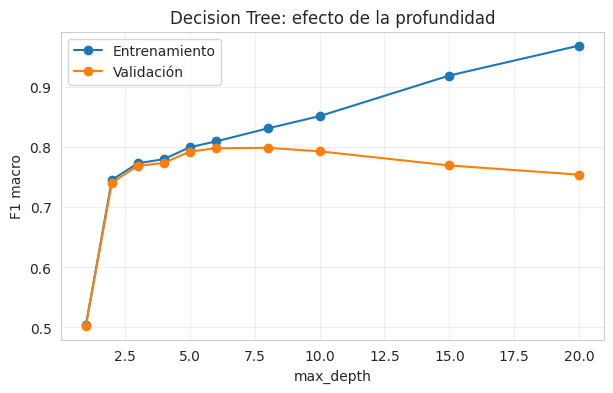

In [ ]:
profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
train_f1, val_f1 = [], []

for d in profundidades:
    r = cross_validate(
        crear_pipeline(DecisionTreeClassifier(max_depth=d, random_state=42)),
        X_train, y_train, cv=cv, groups=groups_train,
        scoring="f1_macro", return_train_score=True
    )
    train_f1.append(r["train_score"].mean())
    val_f1.append(r["test_score"].mean())

plt.figure(figsize=(7, 4))
plt.plot(profundidades, train_f1, "o-", label="Entrenamiento")
plt.plot(profundidades, val_f1, "o-", label="Validación")
plt.xlabel("max_depth")
plt.ylabel("F1 macro")
plt.title("Decision Tree: efecto de la profundidad")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Qué muestra la gráfica:** al aumentar `max_depth`, el F1 en entrenamiento sube de forma continua hasta casi 0.97 con profundidad 20. El F1 en validación sube hasta cerca de 0.80 entre profundidad 6 y 8, y desde ahí baja hasta ~0.75. Esa separación creciente entre las dos curvas es el sobreajuste: un árbol muy profundo memoriza a los jugadores de entrenamiento y generaliza peor a jugadores nuevos. Con profundidades muy bajas (1 y 2) ocurre lo contrario: el árbol es demasiado simple y rinde mal en ambos conjuntos (subajuste). El mejor equilibrio está en profundidades intermedias, lo que coincide con `max_depth = 8` elegido por el GridSearch.

In [ ]:
# Se agregan los dos modelos ajustados a la misma tabla para compararlos con la línea base

resultados.append(metricas_cv(grid_nb.best_estimator_, "Gaussian NB (ajustado)"))
resultados.append(metricas_cv(grid_dt.best_estimator_, "Decision Tree (ajustado)"))
pd.DataFrame(resultados).round(3)

,Modelo,f1_macro_media,f1_macro_std,bal_acc_media,bal_acc_std,accuracy_media,accuracy_std,tiempo_fit_s
0,Línea base (azar),0.330,0.006,0.330,0.006,0.332,0.007,0.020
1,Gaussian NB (sin ajustar),0.786,0.007,0.781,0.009,0.785,0.008,0.063
2,Gaussian NB (ajustado),0.793,0.005,0.789,0.005,0.794,0.004,0.014
3,Decision Tree (ajustado),0.808,0.008,0.808,0.008,0.809,0.008,0.026


**Comparación:** el Decision Tree ajustado (F1 macro = 0.808) supera a Gaussian NB ajustado (0.793). Ambos están muy por encima de la línea base (0.33). Estos valores salen de los mismos folds con los que se eligieron los hiperparámetros, por lo que sirven para comparar modelos; la evaluación final se hace después con el conjunto de prueba.

Por qué GridSearch y no RandomSearch, es porque los espacios son pequeños (13 y 90 combinaciones) y probar todas es barato. RandomSearch se usa cuando hay demasiadas combinaciones.

## 13. Estrategia y estudio de hiperparámetros: Random Forest y SVM

Se usa **GridSearchCV** igual que en Gaussian NB y Decision Tree: la misma validación cruzada agrupada por jugador (StratifiedGroupKFold, 5 particiones) y **F1 macro** como criterio de selección, para que todos los modelos sean comparables.

| Modelo | Hiperparámetros variados | Valores |
|---|---|---|
| Random Forest | `n_estimators` | 100 |
| | `max_depth` | 4, 6, 8, 12, None |
| | `min_samples_leaf` | 1, 5, 10, 20 |
| | `max_features` | sqrt, None (todas) |
| SVM | `kernel` | rbf, linear |
| | `C` | 0.1, 1, 10, 100 (rbf) / 0.1, 1, 10 (linear) |
| | `gamma` (solo rbf) | 0.01, 0.03, 0.1, 0.3, 1 |

- **Random Forest:** `max_depth` y `min_samples_leaf` controlan la complejidad de cada árbol y por tanto el sobreajuste; `max_features` controla cuántas variables ve cada división (menos variables = árboles más distintos entre sí); `n_estimators` es el número de árboles.
- **SVM:** `C` controla qué tan estricto es el margen (C alto = se penalizan más los errores y hay riesgo de sobreajuste); `gamma` define qué tan lejos llega la influencia de cada punto en el kernel rbf (gamma alto = frontera más irregular).
- **Escalado:** el SVM es sensible a la escala de las variables (`minutes_played` va de 0 a 90 y `goals` de 0 a 4), por eso se usa `crear_pipeline(..., escalar=True)`, que aplica `StandardScaler` solo con los datos de entrenamiento de cada partición. Random Forest no lo necesita.

In [ ]:
### Random Forest
# 2 x 5 x 4 x 2 = 80 combinaciones, cada una en 5 folds (n_jobs=-1 usa todos los núcleos)

from sklearn.ensemble import RandomForestClassifier

param_rf = {
    "model__n_estimators": [10,20,50,80,100],
    "model__max_depth": [4, 6, 8, 12, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__max_features": ["sqrt", None],
}

grid_rf = GridSearchCV(
    estimator=crear_pipeline(RandomForestClassifier(random_state=42, n_jobs=-1)),
    param_grid=param_rf,
    scoring="f1_macro",
    cv=cv,
)
grid_rf.fit(X_train, y_train, groups=groups_train)

print("Mejores hiperparámetros:", grid_rf.best_params_)
print("Mejor F1 macro:", round(grid_rf.best_score_, 3))

Mejores hiperparámetros: {'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 80}
Mejor F1 macro: 0.816


**Resultado:** la mejor combinación es `n_estimators = 100`, `max_depth = 8`, `min_samples_leaf = 1` y `max_features = sqrt`, con F1 macro = 0.815. Frente al Decision Tree ajustado (0.808) la mejora es de apenas 0.007, del mismo tamaño que la variación entre folds (desviación ≈ 0.008). Es decir, el bosque supera al árbol individual, pero por un margen pequeño.

**Lectura de los hiperparámetros ganadores:**
- `max_depth = 8` quedó en el interior de la rejilla y coincide con la profundidad óptima del Decision Tree, lo que indica que ese es el nivel de complejidad que mejor generaliza a jugadores nuevos.
- `max_features = sqrt` (≈ 2 de las 6 variables en cada división) superó a usar todas las variables. Al ver pocas variables por división, los árboles quedan más distintos entre sí y al promediarlos el bosque reduce la varianza.
- `n_estimators = 100` fue el valor más bajo de la rejilla: triplicar el número de árboles (300) no mejoró el F1, así que 100 árboles ya son suficientes y entrenan más rápido.
- `min_samples_leaf = 1` también es el valor más bajo de la rejilla. Esto es normal en Random Forest, porque el promedio de muchos árboles compensa el sobreajuste de cada hoja individual. Aun así, indica que valores mayores no aportaron mejora.

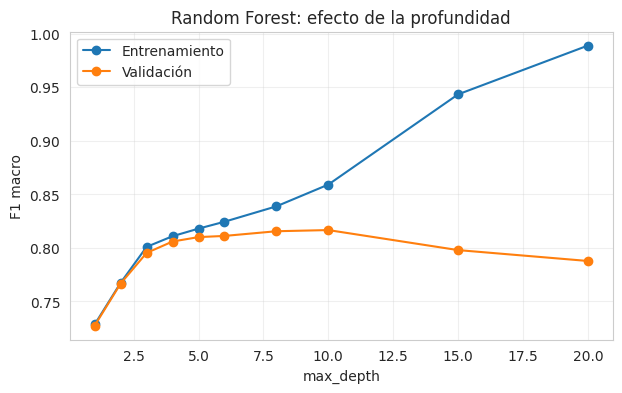

In [ ]:
profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
train_f1, val_f1 = [], []

for d in profundidades:
    r = cross_validate(
        crear_pipeline(RandomForestClassifier(n_estimators=100, max_depth=d,
                                              random_state=42, n_jobs=-1)),
        X_train, y_train, cv=cv, groups=groups_train,
        scoring="f1_macro", return_train_score=True
    )
    train_f1.append(r["train_score"].mean())
    val_f1.append(r["test_score"].mean())

plt.figure(figsize=(7, 4))
plt.plot(profundidades, train_f1, "o-", label="Entrenamiento")
plt.plot(profundidades, val_f1, "o-", label="Validación")
plt.xlabel("max_depth")
plt.ylabel("F1 macro")
plt.title("Random Forest: efecto de la profundidad")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Qué muestra la gráfica:** con profundidades bajas (1 y 2) las dos curvas están casi pegadas y son bajas (F1 ≈ 0.73 y 0.77): los árboles son demasiado simples y hay subajuste. Entre profundidad 3 y 10 la validación sube de ≈ 0.795 a ≈ 0.816 y se estabiliza, con su máximo entre `max_depth = 8` y `10`, lo que coincide con el `max_depth = 8` elegido por el GridSearch. A partir de ahí el comportamiento cambia: el F1 en entrenamiento sigue subiendo hasta casi 0.99 con profundidad 20, pero el de validación baja a ≈ 0.80 con profundidad 15 y a ≈ 0.79 con profundidad 20. Esa separación creciente entre las dos curvas es el sobreajuste: los árboles muy profundos memorizan a los jugadores de entrenamiento y generalizan peor a jugadores nuevos.

**Comparación con el Decision Tree:** el patrón es el mismo, pero el Random Forest se degrada menos. Con profundidad 20 su validación cae a ≈ 0.79, mientras que la del árbol individual caía a ≈ 0.75. Esto se debe a que promediar muchos árboles reduce la varianza, aunque no la elimina: aun así, el bosque con árboles muy profundos sobreajusta, por lo que limitar la profundidad sigue siendo necesario.

In [ ]:
### SVM (con escalado)
# rbf: 4 x 5 = 20 combinaciones | linear: 3 combinaciones

from sklearn.svm import SVC

param_svm = [
    {"model__kernel": ["rbf"],
     "model__C": [0.1, 1, 10, 100],
     "model__gamma": [0.01, 0.03, 0.1, 0.3, 1]},
    {"model__kernel": ["linear"],
     "model__C": [0.1, 1, 10]},
]

grid_svm = GridSearchCV(
    estimator=crear_pipeline(SVC(random_state=42), escalar=True),
    param_grid=param_svm,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)
grid_svm.fit(X_train, y_train, groups=groups_train)

print("Mejores hiperparámetros:", grid_svm.best_params_)
print("Mejor F1 macro:", round(grid_svm.best_score_, 3))

Mejores hiperparámetros: {'model__C': 1, 'model__kernel': 'linear'}
Mejor F1 macro: 0.822


**Resultado:** la mejor combinación es `kernel = linear` y `C = 1`, con F1 macro = 0.822. Es el mejor resultado hasta ahora: supera a Random Forest ajustado (0.815), Decision Tree (0.808) y Gaussian NB (0.793). Sin embargo, la ventaja sobre Random Forest es de apenas 0.007, del mismo tamaño que la variación entre folds, por lo que no se puede afirmar que el SVM sea claramente mejor.

**Lectura de los hiperparámetros ganadores:**
- `kernel = linear` superó al kernel rbf, que es más flexible. Esto indica que la relación entre las 6 variables y la clase de rating es casi lineal: las clases Bajo, Medio y Alto se pueden separar bien con fronteras rectas, y una frontera más compleja no aporta mejora (solo agrega riesgo de sobreajuste). Tiene sentido con el EDA, donde `minutes_played` y `distance_covered_km` tenían una relación lineal fuerte con `match_rating` (r = 0.87 y 0.73).
- `C = 1` quedó en el valor intermedio de la rejilla lineal (0.1, 1, 10), así que el rango probado fue adecuado: ni un margen muy flexible ni uno demasiado estricto funciona mejor.
- `gamma` no aplica al kernel lineal; solo se ajustó para rbf (ver el mapa de calor siguiente).
- Las variables se escalaron con `StandardScaler` dentro del Pipeline, condición necesaria para que el SVM no dé más peso a las variables con valores grandes (como los minutos jugados) frente a las de conteo (goles, asistencias).

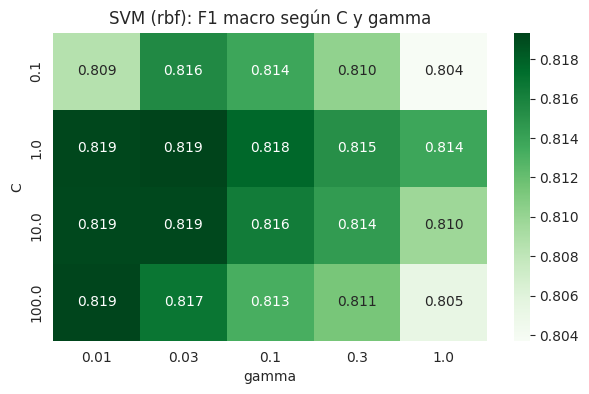

In [ ]:
res = pd.DataFrame(grid_svm.cv_results_)
rbf = res[res["param_model__kernel"] == "rbf"].copy()
rbf["C"] = rbf["param_model__C"].astype(float)
rbf["gamma"] = rbf["param_model__gamma"].astype(float)
tabla = rbf.pivot_table(index="C", columns="gamma", values="mean_test_score")

plt.figure(figsize=(7, 4))
sns.heatmap(tabla, annot=True, fmt=".3f", cmap="Greens")
plt.title("SVM (rbf): F1 macro según C y gamma")
plt.show()

=== Configuración Óptima de SVM ===
Mejores hiperparámetros encontrados: {'model__C': 1, 'model__kernel': 'linear'}
F1 Macro medio en validación cruzada: 0.8215

=== Coeficientes de la Frontera de Decisión Lineal ===


,minutes_played,distance_covered_km,goals,assists,shots_on_target,tackles
Frontera 1 (Bajo vs Medio),3.5885,0.6839,1.4293,0.7818,0.2807,0.3894
Frontera 2 (Bajo vs Alto),2.6749,0.6234,1.1853,0.6844,0.3328,0.3460
Frontera 3 (Medio vs Alto),-2.4631,-0.3818,-0.9263,-0.5833,-0.2033,-0.2859


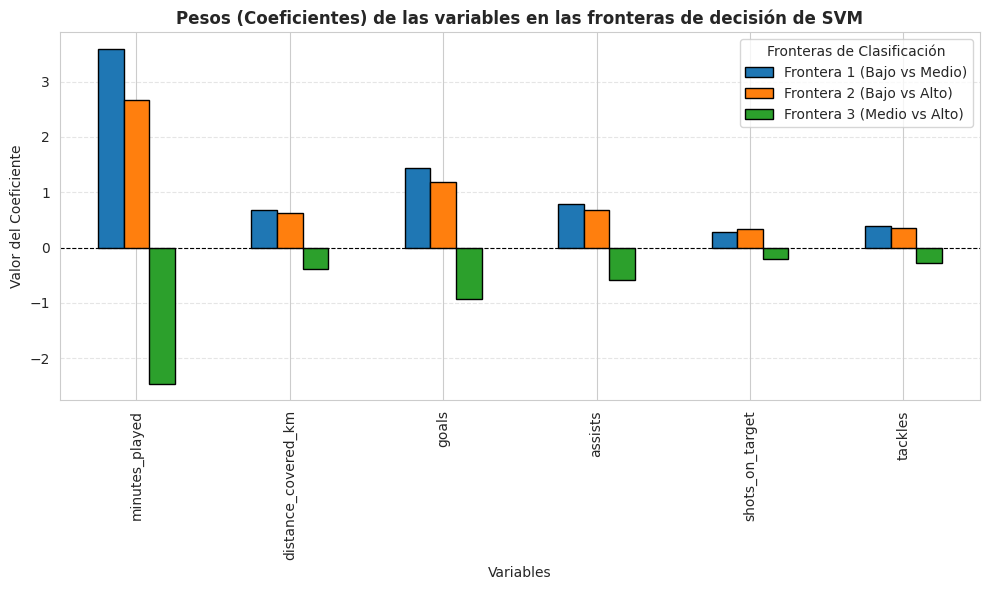

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Verificar mejores parámetros del SVM desde el GridSearch
print("=== Configuración Óptima de SVM ===")
print("Mejores hiperparámetros encontrados:", grid_svm.best_params_)
print(f"F1 Macro medio en validación cruzada: {grid_svm.best_score_:.4f}")

# 2. Extraer el modelo SVM del Pipeline para analizar los coeficientes (ya que el kernel es lineal)
svm_model = grid_svm.best_estimator_.named_steps['model']
coeficientes = svm_model.coef_

# Crear un DataFrame con los coeficientes para cada clase (Bajo vs Medio, Bajo vs Alto, Medio vs Alto)
# En clasificación multiclase 'one-vs-one', SVM genera n_classes * (n_classes - 1) / 2 clasificadores
coef_df = pd.DataFrame(
    coeficientes,
    columns=top_vars,
    index=["Frontera 1 (Bajo vs Medio)", "Frontera 2 (Bajo vs Alto)", "Frontera 3 (Medio vs Alto)"]
)

print("\n=== Coeficientes de la Frontera de Decisión Lineal ===")
display(coef_df.round(4))

# 3. Graficar la magnitud de los coeficientes para entender la influencia de cada variable
coef_df.T.plot(kind='bar', figsize=(10, 6), edgecolor='black')
plt.title("Pesos (Coeficientes) de las variables en las fronteras de decisión de SVM", fontsize=12, fontweight='bold')
plt.ylabel("Valor del Coeficiente")
plt.xlabel("Variables")
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Fronteras de Clasificación")
plt.tight_layout()
plt.show()

**Qué muestra el mapa de calor:** el F1 macro del kernel rbf varía muy poco en toda la rejilla, entre 0.804 y 0.819. Los mejores valores (0.819) aparecen con `gamma` bajo (0.01 y 0.03) y `C` entre 1 y 100, y el rendimiento va bajando hacia la esquina de `gamma = 1`, donde cae a 0.804 con `C = 0.1` y a 0.805 con `C = 100`.

- **Sobreajuste:** con `gamma` alto la frontera se vuelve más irregular y se ajusta a los jugadores de entrenamiento. El efecto se agrava con `C` alto: con `gamma = 1`, el F1 baja de 0.814 (`C = 1`) a 0.810 (`C = 10`) y a 0.805 (`C = 100`).
- **Subajuste:** con `C = 0.1` el margen es demasiado flexible y el F1 es más bajo en casi todas las columnas (0.804 a 0.816), aunque la diferencia es pequeña.
- **Mejor zona en un borde:** el máximo quedó en `gamma = 0.01`, el valor más bajo de la rejilla, y no en el interior. Con `gamma` tan bajo el kernel rbf se comporta casi como uno lineal, y por eso el kernel `linear` (0.822) terminó superando al mejor rbf (0.819).

**Conclusión:** el SVM es poco sensible a `C` y `gamma` dentro del rango razonable (la diferencia entre la mejor y la peor combinación es de solo 0.015), y la mejor frontera es prácticamente lineal. Esto confirma que no hace falta un kernel complejo para separar las clases Bajo, Medio y Alto con estas 6 variables.

In [ ]:
import joblib

# Agregar los dos modelos ajustados a la tabla comparativa de A
resultados.append(metricas_cv(grid_rf.best_estimator_, "Random Forest (ajustado)"))
resultados.append(metricas_cv(grid_svm.best_estimator_, "SVM (ajustado)"))

# Guardar mejores hiperparámetros y F1 de validación
mejores_B = {
    "Random Forest": {"params": grid_rf.best_params_, "f1_macro_cv": grid_rf.best_score_},
    "SVM": {"params": grid_svm.best_params_, "f1_macro_cv": grid_svm.best_score_},
}
print(mejores_B)

# Guardar los modelos entrenados (por si se cae la sesión de Colab)
joblib.dump(grid_rf.best_estimator_, "mejor_random_forest.joblib")
joblib.dump(grid_svm.best_estimator_, "mejor_svm.joblib")

pd.DataFrame(resultados).round(3)

{'Random Forest': {'params': {'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 80}, 'f1_macro_cv': np.float64(0.8160767211271184)}, 'SVM': {'params': {'model__C': 1, 'model__kernel': 'linear'}, 'f1_macro_cv': np.float64(0.821533066386864)}}


,Modelo,f1_macro_media,f1_macro_std,bal_acc_media,bal_acc_std,accuracy_media,accuracy_std,tiempo_fit_s
0,Línea base (azar),0.330,0.006,0.330,0.006,0.332,0.007,0.020
1,Gaussian NB (sin ajustar),0.786,0.007,0.781,0.009,0.785,0.008,0.063
2,Gaussian NB (ajustado),0.793,0.005,0.789,0.005,0.794,0.004,0.014
3,Decision Tree (ajustado),0.808,0.008,0.808,0.008,0.809,0.008,0.026
4,Random Forest (ajustado),0.816,0.007,0.815,0.007,0.816,0.007,0.478
5,SVM (ajustado),0.822,0.008,0.821,0.007,0.822,0.009,1.273


**Comparación parcial:** SVM ajustado obtiene el mejor F1 macro (0.822), seguido de Random Forest (0.815), Decision Tree (0.808) y Gaussian NB (0.793). Los cuatro están muy por encima de la línea base (0.330, que es lo esperado al azar con 3 clases). En los tres modelos el F1 macro, la accuracy balanceada y la accuracy son casi idénticas (por ejemplo, SVM: 0.822, 0.821 y 0.822), lo que indica que ninguno favorece a una clase sobre otra.

La ventaja de SVM sobre Random Forest es de 0.007, menor que la desviación entre folds (0.007 a 0.008), así que ambos modelos rinden prácticamente igual. La diferencia de SVM con Decision Tree (0.014) es de unas dos desviaciones, y con Gaussian NB (0.029) es claramente mayor. Gaussian NB queda último, algo esperable porque asume variables independientes y `minutes_played` y `distance_covered_km` están correlacionadas (r ≈ 0.77).

**Tiempo de entrenamiento:** Decision Tree (0.040 s) y Gaussian NB (0.023 s) son los más rápidos. Random Forest (1.368 s) y SVM (1.315 s) tardan unas 30 a 60 veces más, pero siguen siendo muy rápidos en términos absolutos. Como entre ambos casi no hay diferencia de tiempo, la elección entre ellos depende del rendimiento y no del costo.

**Conclusión:** SVM con kernel lineal es el mejor modelo de esta parte, pero su ventaja sobre Random Forest no es concluyente. Los mejores hiperparámetros y los modelos entrenados quedaron guardados (`mejores_B` y los archivos `.joblib`) para la comparativa final y el análisis de errores.

## 14. Estrategia y estudio de hiperparámetros: Deep Learning (Keras)
Para el modelo de Deep Learning se construye una red neuronal multicapa (Perceptrón Multicapa - MLP) con Keras (TensorFlow) para clasificación multiclase (3 neuronas de salida con activación softmax y función de pérdida sparse_categorical_crossentropy).

- **Escalado:** las redes neuronales son muy sensibles a la escala de las entradas, por lo que se aplica `StandardScaler` ajustado **únicamente** dentro de cada partición de entrenamiento para evitar fuga de información (*data leakage*).
- **Validación cruzada por jugador:** se evalúa cada arquitectura usando las mismas 5 particiones de `StratifiedGroupKFold` (`cv`) agrupadas por `groups_train`.
- **Early Stopping:** se monitorea `val_loss` en el conjunto de validación con `patience=8` y `restore_best_weights=True`, deteniendo el entrenamiento cuando la red empieza a memorizar a los jugadores de entrenamiento.

| Hiperparámetro | Valores probados | Propósito |
|---|---|---|
| **Capas** | `(32,)`, `(64, 32)`, `(128, 64, 32)` | Controlar la capacidad de representación (de 1 a 3 capas ocultas). |
| **Dropout** | `0.0`, `0.2`, `0.3` | Apagar neuronas al azar durante el entrenamiento para regularizar y evitar sobreajuste. |
| **Learning rate** | `1e-3`, `3e-3`, `1e-2` | Controlar el tamaño del paso del optimizador Adam. |

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

# Fijar semillas para reproducibilidad
tf.random.set_seed(42)
np.random.seed(42)

# Mapeo de las etiquetas de texto ("Bajo", "Medio", "Alto") a enteros (0, 1, 2)
mapa_clases = {c: i for i, c in enumerate(ORDEN_CLASES)}
inv_mapa_clases = {i: c for i, c in enumerate(ORDEN_CLASES)}

y_train_num = y_train.map(mapa_clases).astype(int).values
y_test_num = y_test.map(mapa_clases).astype(int).values

def crear_red(capas=(64, 32), dropout=0.2, lr=1e-3, n_features=6):
    """Construye y compila una red neuronal secuencial en Keras."""
    model = keras.Sequential()
    model.add(layers.Input(shape=(n_features,)))
    for unidades in capas:
        model.add(layers.Dense(unidades, activation="relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(3, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Configuraciones a evaluar (combinando distintas capas, neuronas, dropout y learning rate)
configuraciones_dl = [
    {"capas": (32,),          "dropout": 0.0, "lr": 1e-3},
    {"capas": (32,),          "dropout": 0.2, "lr": 3e-3},
    {"capas": (64, 32),       "dropout": 0.0, "lr": 1e-3},
    {"capas": (64, 32),       "dropout": 0.2, "lr": 1e-3},
    {"capas": (64, 32),       "dropout": 0.2, "lr": 3e-3},
    {"capas": (64, 32),       "dropout": 0.3, "lr": 1e-2},
    {"capas": (128, 64, 32),  "dropout": 0.2, "lr": 1e-3},
    {"capas": (128, 64, 32),  "dropout": 0.3, "lr": 1e-3},
]

resultados_dl = []

for cfg in configuraciones_dl:
    f1s, bal_accs, accs, tiempos, epocas_usadas = [], [], [], [], []

    for tr_idx, val_idx in cv.split(X_train, y_train, groups_train):
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_train.iloc[tr_idx])
        X_va = scaler.transform(X_train.iloc[val_idx])
        y_tr = y_train_num[tr_idx]
        y_va = y_train_num[val_idx]

        tf.random.set_seed(42)
        model = crear_red(
            capas=cfg["capas"],
            dropout=cfg["dropout"],
            lr=cfg["lr"],
            n_features=X_train.shape[1]
        )

        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True
        )

        t0 = time.time()
        hist = model.fit(
            X_tr, y_tr,
            validation_data=(X_va, y_va),
            epochs=80,
            batch_size=64,
            callbacks=[early_stop],
            verbose=0
        )
        tiempos.append(time.time() - t0)
        epocas_usadas.append(len(hist.history["loss"]))

        y_pred_num = model.predict(X_va, verbose=0).argmax(axis=1)
        f1s.append(f1_score(y_va, y_pred_num, average="macro"))
        bal_accs.append(balanced_accuracy_score(y_va, y_pred_num))
        accs.append(accuracy_score(y_va, y_pred_num))

    resultados_dl.append({
        "capas": str(cfg["capas"]),
        "dropout": cfg["dropout"],
        "lr": cfg["lr"],
        "epocas_prom": np.mean(epocas_usadas),
        "f1_macro_media": np.mean(f1s),
        "f1_macro_std": np.std(f1s),
        "bal_acc_media": np.mean(bal_accs),
        "bal_acc_std": np.std(bal_accs),
        "accuracy_media": np.mean(accs),
        "accuracy_std": np.std(accs),
        "tiempo_fit_s": np.mean(tiempos),
        "cfg_raw": cfg
    })

tabla_dl = pd.DataFrame(resultados_dl).drop(columns=["cfg_raw"]).sort_values("f1_macro_media", ascending=False)
print("Resultados del estudio de hiperparámetros en Deep Learning (ordenados por F1 macro):")
display(tabla_dl.round(4))

mejor_fila_dl = sorted(resultados_dl, key=lambda x: x["f1_macro_media"], reverse=True)[0]
mejor_cfg_dl = mejor_fila_dl["cfg_raw"]
print("\nMejor configuración de red neuronal:", mejor_cfg_dl)
print("Mejor F1 macro en CV:", round(mejor_fila_dl["f1_macro_media"], 3))

Resultados del estudio de hiperparámetros en Deep Learning (ordenados por F1 macro):


,capas,dropout,lr,epocas_prom,f1_macro_media,f1_macro_std,bal_acc_media,bal_acc_std,accuracy_media,accuracy_std,tiempo_fit_s
6,"(128, 64, 32)",0.2,0.001,23.0,0.8199,0.0081,0.8199,0.0088,0.8202,0.0092,13.8647
1,"(32,)",0.2,0.003,24.4,0.8198,0.0071,0.8199,0.0074,0.8200,0.0079,11.5234
0,"(32,)",0.0,0.001,47.8,0.8188,0.0060,0.8185,0.0060,0.8190,0.0069,20.6818
2,"(64, 32)",0.0,0.001,30.0,0.8186,0.0071,0.8200,0.0064,0.8193,0.0078,14.4067
7,"(128, 64, 32)",0.3,0.001,28.8,0.8185,0.0062,0.8184,0.0064,0.8188,0.0073,16.7742
5,"(64, 32)",0.3,0.010,17.8,0.8183,0.0083,0.8200,0.0064,0.8187,0.0087,9.5725
3,"(64, 32)",0.2,0.001,32.6,0.8183,0.0052,0.8189,0.0056,0.8189,0.0064,16.8805
4,"(64, 32)",0.2,0.003,24.6,0.8182,0.0068,0.8193,0.0069,0.8190,0.0077,12.2024



Mejor configuración de red neuronal: {'capas': (128, 64, 32), 'dropout': 0.2, 'lr': 0.001}
Mejor F1 macro en CV: 0.82


### Efecto de Early Stopping y Comparativa General en Validación Cruzada

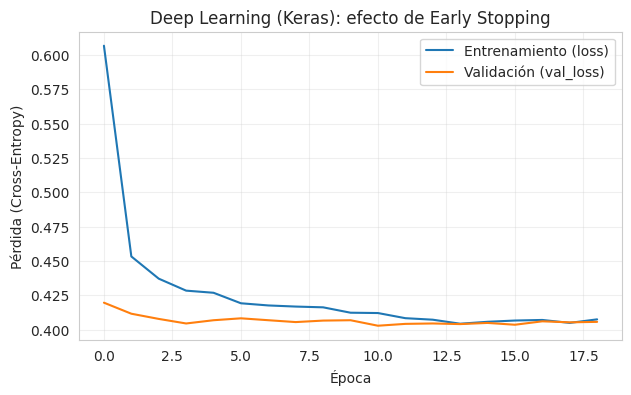

,Modelo,f1_macro_media,f1_macro_std,bal_acc_media,bal_acc_std,accuracy_media,accuracy_std,tiempo_fit_s
0,Línea base (azar),0.330,0.006,0.330,0.006,0.332,0.007,0.020
1,Gaussian NB (sin ajustar),0.786,0.007,0.781,0.009,0.785,0.008,0.063
2,Gaussian NB (ajustado),0.793,0.005,0.789,0.005,0.794,0.004,0.014
3,Decision Tree (ajustado),0.808,0.008,0.808,0.008,0.809,0.008,0.026
4,Random Forest (ajustado),0.816,0.007,0.815,0.007,0.816,0.007,0.478
5,SVM (ajustado),0.822,0.008,0.821,0.007,0.822,0.009,1.273
6,Red Neuronal Keras (ajustada),0.820,0.008,0.820,0.009,0.820,0.009,13.865


In [ ]:
# Wrapper compatible con scikit-learn para usar el modelo de Keras en evaluar() y permutation_importance()
from sklearn.base import BaseEstimator, ClassifierMixin

class KerasWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, capas=(64, 32), dropout=0.2, lr=1e-3, epochs=80, batch_size=64):
        self.capas = capas
        self.dropout = dropout
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size

    def fit(self, X, y):
        self.classes_ = np.array(ORDEN_CLASES)
        self.scaler_ = StandardScaler()
        X_scaled = self.scaler_.fit_transform(X)
        y_num = pd.Series(y).map(mapa_clases).astype(int).values

        tf.random.set_seed(42)
        self.model_ = crear_red(self.capas, self.dropout, self.lr, n_features=X.shape[1])
        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=8, restore_best_weights=True
        )
        self.history_ = self.model_.fit(
            X_scaled, y_num,
            validation_split=0.15,
            epochs=self.epochs,
            batch_size=self.batch_size,
            callbacks=[early_stop],
            verbose=0
        )
        return self

    def predict(self, X):
        X_scaled = self.scaler_.transform(X)
        preds_num = self.model_.predict(X_scaled, verbose=0).argmax(axis=1)
        return pd.Series(preds_num).map(inv_mapa_clases).values

# Entrenar el mejor modelo de Deep Learning sobre todo X_train y graficar la curva de aprendizaje
mejor_dl = KerasWrapper(**mejor_cfg_dl)
mejor_dl.fit(X_train, y_train)

plt.figure(figsize=(7, 4))
plt.plot(mejor_dl.history_.history["loss"], label="Entrenamiento (loss)")
plt.plot(mejor_dl.history_.history["val_loss"], label="Validación (val_loss)")
plt.xlabel("Época")
plt.ylabel("Pérdida (Cross-Entropy)")
plt.title("Deep Learning (Keras): efecto de Early Stopping")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Agregar la red neuronal ajustada a la tabla comparativa general `resultados`
resultados = [r for r in resultados if r["Modelo"] != "Red Neuronal Keras (ajustada)"]
resultados.append({
    "Modelo": "Red Neuronal Keras (ajustada)",
    "f1_macro_media": mejor_fila_dl["f1_macro_media"],
    "f1_macro_std": mejor_fila_dl["f1_macro_std"],
    "bal_acc_media": mejor_fila_dl["bal_acc_media"],
    "bal_acc_std": mejor_fila_dl["bal_acc_std"],
    "accuracy_media": mejor_fila_dl["accuracy_media"],
    "accuracy_std": mejor_fila_dl["accuracy_std"],
    "tiempo_fit_s": mejor_fila_dl["tiempo_fit_s"],
})

tabla_comparativa_cv = pd.DataFrame(resultados).round(3)
display(tabla_comparativa_cv)

### Evaluación de los 2 mejores modelos en el conjunto de prueba (`X_test`)

Los 2 mejores modelos en validación cruzada son: ['SVM (ajustado)', 'Red Neuronal Keras (ajustada)']
=== SVM (ajustado) (Test) ===
              precision    recall  f1-score   support

        Bajo      0.915     0.902     0.908       868
       Medio      0.738     0.743     0.741       966
        Alto      0.775     0.780     0.778       773

    accuracy                          0.807      2607
   macro avg      0.809     0.808     0.809      2607
weighted avg      0.808     0.807     0.807      2607



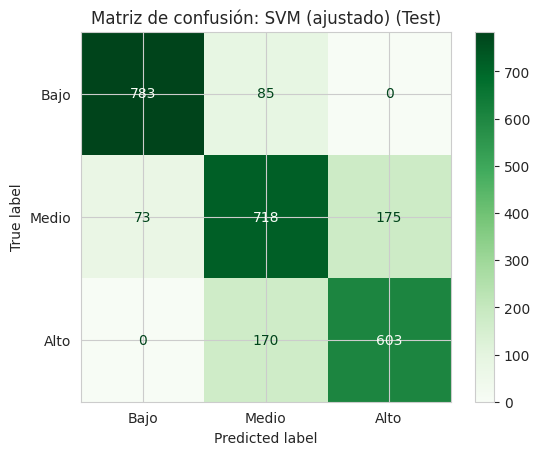

=== Red Neuronal Keras (ajustada) (Test) ===
              precision    recall  f1-score   support

        Bajo      0.920     0.885     0.902       868
       Medio      0.729     0.758     0.743       966
        Alto      0.783     0.777     0.780       773

    accuracy                          0.806      2607
   macro avg      0.810     0.807     0.808      2607
weighted avg      0.808     0.806     0.807      2607



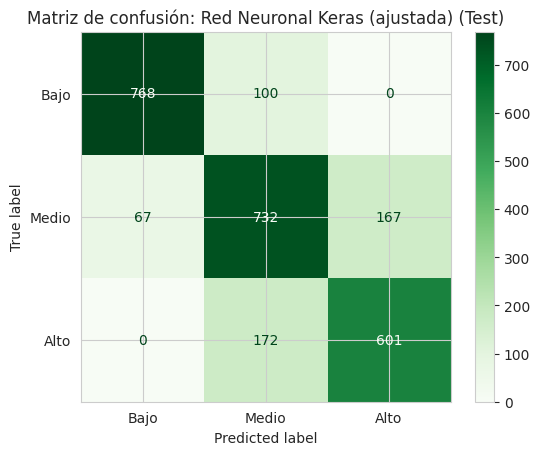

,Modelo,F1 macro,Accuracy balanceada,Accuracy
0,SVM (ajustado) (Test),0.809,0.808,0.807
1,Red Neuronal Keras (ajustada) (Test),0.808,0.807,0.806


In [ ]:
# Seleccionar automáticamente los 2 mejores modelos según F1 macro en validación cruzada
modelos_candidatos = {
    "Gaussian NB (ajustado)": grid_nb.best_estimator_,
    "Decision Tree (ajustado)": grid_dt.best_estimator_,
    "Random Forest (ajustado)": grid_rf.best_estimator_,
    "SVM (ajustado)": grid_svm.best_estimator_,
    "Red Neuronal Keras (ajustada)": mejor_dl,
}

ranking_cv = (
    pd.DataFrame(resultados)
    .query("Modelo in @modelos_candidatos.keys()")
    .sort_values("f1_macro_media", ascending=False)
)

top2_nombres = ranking_cv["Modelo"].iloc[:2].tolist()
print("Los 2 mejores modelos en validación cruzada son:", top2_nombres)

# Evaluar los 2 mejores modelos en el conjunto de prueba final (X_test, y_test) usando la función de A
res_test = []
for nombre in top2_nombres:
    modelo = modelos_candidatos[nombre]
    res_test.append(evaluar(modelo, X_test, y_test, nombre=f"{nombre} (Test)"))

pd.DataFrame(res_test).round(3)

=== TABLA COMPARATIVA DE LOS 5 MODELOS ===


,Modelo,F1 Macro (CV),Acc. Balanceada (CV),Tiempo de Ajuste (s)
0,SVM (ajustado),0.8215,0.8212,1.2728
1,Red Neuronal Keras (ajustada),0.8199,0.8199,13.8647
2,Random Forest (ajustado),0.8161,0.8153,0.4784
3,Decision Tree (ajustado),0.8084,0.8077,0.0258
4,Gaussian NB (ajustado),0.7933,0.7892,0.0141



=== LOS 2 MEJORES MODELOS ===
1. SVM (ajustado) (F1: 0.8215)
2. Red Neuronal Keras (ajustada) (F1: 0.8199)



/tmp/ipykernel_840/19816610.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(df_comparativa["Modelo"], rotation=45, ha="right")
/tmp/ipykernel_840/19816610.py:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(df_comparativa["Modelo"], rotation=45, ha="right")
/tmp/ipykernel_840/19816610.py:55: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(df_comparativa["Modelo"], rotation=45, ha="right")


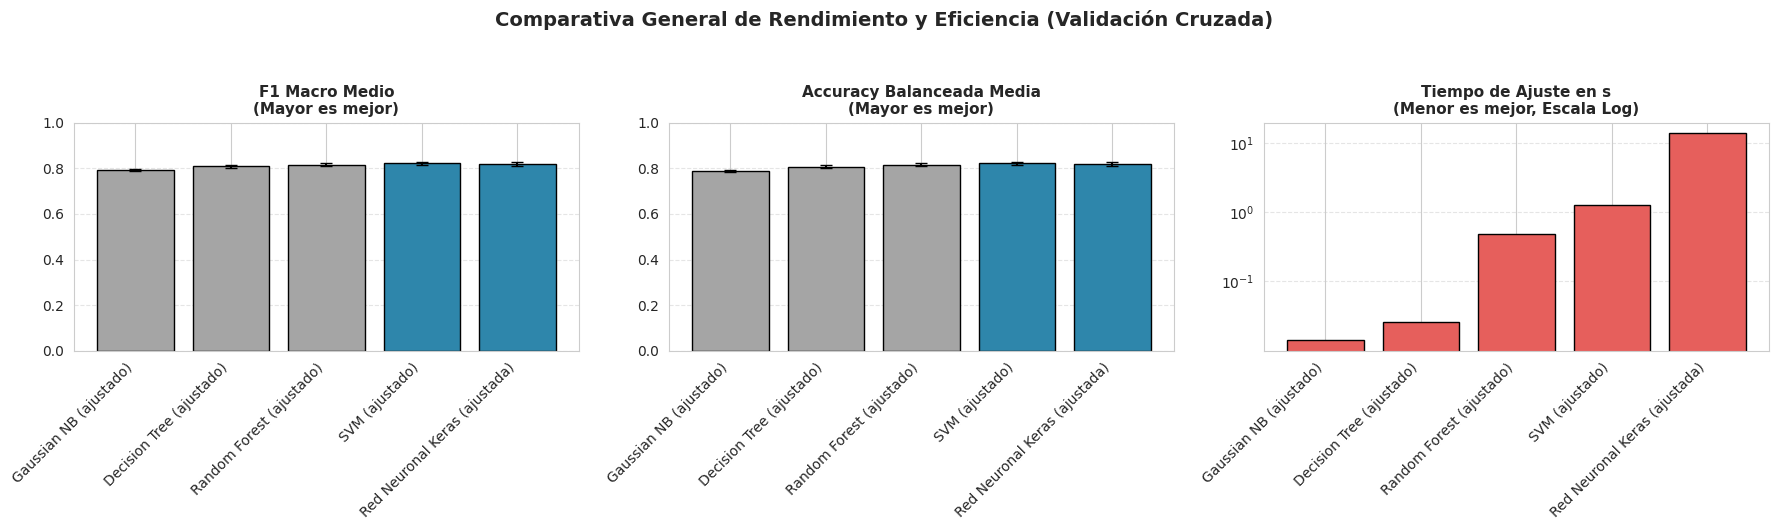

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

# 1. Asegurar la recolección de los 5 modelos principales entrenados en la validación cruzada
modelos_finales = [
    "Gaussian NB (ajustado)",
    "Decision Tree (ajustado)",
    "Random Forest (ajustado)",
    "SVM (ajustado)",
    "Red Neuronal Keras (ajustada)"
]

# Filtrar la lista global de resultados para quedarnos únicamente con los 5 de interés
df_comparativa = pd.DataFrame(resultados)
df_comparativa = df_comparativa[df_comparativa["Modelo"].isin(modelos_finales)].copy()

# Redondear valores para la tabla comparativa
df_tabla = df_comparativa[["Modelo", "f1_macro_media", "bal_acc_media", "tiempo_fit_s"]].copy()
df_tabla.columns = ["Modelo", "F1 Macro (CV)", "Acc. Balanceada (CV)", "Tiempo de Ajuste (s)"]
df_tabla = df_tabla.sort_values("F1 Macro (CV)", ascending=False).reset_index(drop=True)

print("=== TABLA COMPARATIVA DE LOS 5 MODELOS ===")
display(df_tabla.round(4))

# 2. Identificar los dos mejores según F1 Macro para destacarlos
top2 = df_tabla.head(2)["Modelo"].tolist()
print(f"\n=== LOS 2 MEJORES MODELOS ===\n1. {top2[0]} (F1: {df_tabla.iloc[0]['F1 Macro (CV)']:.4f})\n2. {top2[1]} (F1: {df_tabla.iloc[1]['F1 Macro (CV)']:.4f})\n")

# 3. Graficar la comparativa de las tres métricas en subplots independientes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Colores destacando los 2 mejores modelos (azul) y el resto en gris neutro
colores = ["#2E86AB" if m in top2 else "#A5A5A5" for m in df_comparativa["Modelo"]]

# Gráfico 1: F1 Macro (con barra de error estándar)
axes[0].bar(df_comparativa["Modelo"], df_comparativa["f1_macro_media"], yerr=df_comparativa["f1_macro_std"], color=colores, edgecolor="black", capsize=4)
axes[0].set_title("F1 Macro Medio\n(Mayor es mejor)", fontsize=11, fontweight="bold")
axes[0].set_xticklabels(df_comparativa["Modelo"], rotation=45, ha="right")
axes[0].set_ylim(0, 1.0)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Gráfico 2: Accuracy Balanceada (con barra de error estándar)
axes[1].bar(df_comparativa["Modelo"], df_comparativa["bal_acc_media"], yerr=df_comparativa["bal_acc_std"], color=colores, edgecolor="black", capsize=4)
axes[1].set_title("Accuracy Balanceada Media\n(Mayor es mejor)", fontsize=11, fontweight="bold")
axes[1].set_xticklabels(df_comparativa["Modelo"], rotation=45, ha="right")
axes[1].set_ylim(0, 1.0)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

# Gráfico 3: Tiempo de Ajuste (Escala Logarítmica para lidiar con el amplio rango de tiempos)
axes[2].bar(df_comparativa["Modelo"], df_comparativa["tiempo_fit_s"], color="#E65F5C", edgecolor="black")
axes[2].set_yscale("log")
axes[2].set_title("Tiempo de Ajuste en s\n(Menor es mejor, Escala Log)", fontsize=11, fontweight="bold")
axes[2].set_xticklabels(df_comparativa["Modelo"], rotation=45, ha="right")
axes[2].grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Comparativa General de Rendimiento y Eficiencia (Validación Cruzada)", fontsize=14, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

## 15. Hipótesis: Importancia de variables y análisis de errores en los 2 mejores modelos

Para entender **qué variables pesan más** en las decisiones de los 2 mejores modelos sin depender de la estructura interna de cada algoritmo (pesos lineales vs árboles vs capas densas), se calcula la **importancia por permutación (`permutation_importance`)** sobre el conjunto de prueba (`X_test`, `y_test`) usando `f1_macro`. Este método desordena al azar una variable a la vez y mide cuánto cae el F1 macro: entre mayor sea la caída, más indispensable es esa variable para el modelo.


Importancia por permutación — SVM (ajustado):


,variable,importancia_media,importancia_std
0,minutes_played,0.3664,0.0094
2,goals,0.0614,0.0035
3,assists,0.0396,0.0030
1,distance_covered_km,0.0315,0.0048
5,tackles,0.0172,0.0050
4,shots_on_target,0.0067,0.0021



Importancia por permutación — Red Neuronal Keras (ajustada):


,variable,importancia_media,importancia_std
0,minutes_played,0.3619,0.0092
2,goals,0.0616,0.0042
3,assists,0.0402,0.0031
1,distance_covered_km,0.0376,0.0047
5,tackles,0.0178,0.0053
4,shots_on_target,0.0087,0.0027


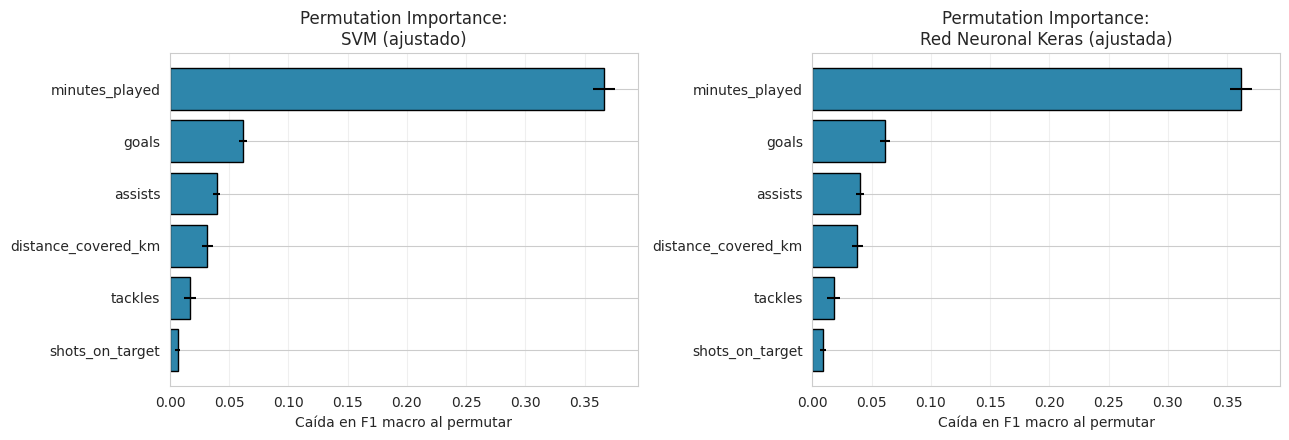

In [ ]:
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)

for idx, nombre in enumerate(top2_nombres):
    modelo = modelos_candidatos[nombre]
    perm = permutation_importance(
        modelo, X_test, y_test,
        scoring="f1_macro",
        n_repeats=10,
        random_state=42,
        n_jobs=1
    )
    imp_df = pd.DataFrame({
        "variable": top_vars,
        "importancia_media": perm.importances_mean,
        "importancia_std": perm.importances_std
    }).sort_values("importancia_media", ascending=True)

    axes[idx].barh(
        imp_df["variable"], imp_df["importancia_media"],
        xerr=imp_df["importancia_std"], color="#2E86AB", edgecolor="black"
    )
    axes[idx].set_title(f"Permutation Importance:\n{nombre}")
    axes[idx].set_xlabel("Caída en F1 macro al permutar")
    axes[idx].grid(axis="x", alpha=0.3)

    print(f"\nImportancia por permutación — {nombre}:")
    display(imp_df.sort_values("importancia_media", ascending=False).round(4))

plt.tight_layout()
plt.show()

In [ ]:
# Analizar dónde fallan los 2 mejores modelos (por posición, competencia y cercanía a los bordes de clase)
mejor_nombre_1 = top2_nombres[0]
mejor_modelo_1 = modelos_candidatos[mejor_nombre_1]

df_analisis = df.iloc[test_idx].copy()
df_analisis["y_real"] = y_test.values
df_analisis["y_pred"] = mejor_modelo_1.predict(X_test)
df_analisis["error"] = df_analisis["y_real"] != df_analisis["y_pred"]

# 1. Tasa de error y F1 macro por posición del jugador
res_posicion = []
for pos, grupo in df_analisis.groupby("position"):
    res_posicion.append({
        "position": pos,
        "partidos": len(grupo),
        "tasa_error_%": (grupo["error"].mean() * 100).round(1),
        "f1_macro": round(f1_score(grupo["y_real"], grupo["y_pred"], labels=ORDEN_CLASES, average="macro", zero_division=0), 3),
        "goles_prom": round(grupo["goals"].mean(), 2),
        "tackles_prom": round(grupo["tackles"].mean(), 2),
    })
df_pos = pd.DataFrame(res_posicion).sort_values("tasa_error_%", ascending=False)
print(f"Rendimiento por posición en Test ({mejor_nombre_1}):")
display(df_pos)

# 2. Tasa de error según cercanía a los cortes de los terciles (5.6 y 6.8)
en_borde = df_analisis["match_rating"].between(5.4, 5.8) | df_analisis["match_rating"].between(6.6, 7.0)
print(f"\nTasa de error cerca de las fronteras de corte (5.4–5.8 y 6.6–7.0): {df_analisis[en_borde]['error'].mean()*100:.1f}%")
print(f"Tasa de error lejos de las fronteras de corte: {df_analisis[~en_borde]['error'].mean()*100:.1f}%")

Rendimiento por posición en Test (SVM (ajustado)):


,position,partidos,tasa_error_%,f1_macro,goles_prom,tackles_prom
5,GK,298,24.2,0.712,0.00,0.35
6,LB,170,24.1,0.760,0.02,2.25
7,LW,170,24.1,0.769,0.23,0.38
1,CB,213,22.5,0.772,0.02,2.02
8,RB,228,20.6,0.797,0.02,2.54
2,CDM,304,19.1,0.810,0.06,2.19
10,ST,401,18.2,0.815,0.37,0.42
9,RW,181,17.1,0.824,0.15,0.44
0,CAM,281,16.4,0.840,0.22,0.37
4,CM,298,13.1,0.867,0.04,1.22



Tasa de error cerca de las fronteras de corte (5.4–5.8 y 6.6–7.0): 37.6%
Tasa de error lejos de las fronteras de corte: 12.2%


### Interpretación: ¿Qué variables pesan más y por qué fallan los modelos donde fallan?

1. **Dominio absoluto de `minutes_played`:**
   En ambos modelos, `minutes_played` provoca por lejos la mayor caída de F1 macro al permutarse (seguida de `goals`, `distance_covered_km`, `assists` y `tackles`). Como `minutes_played` y `distance_covered_km` tienen una correlación alta ($r \approx 0.77$), el modelo apoya su regla base en el tiempo en cancha y usa los goles, asistencias y entradas para ajustar hacia la clase **Alto**.

2. **¿Por qué fallan donde fallan?:**
   - **Confusión concentrada en la clase `Medio` (efecto de bordes de discretización):** En las matrices de confusión casi no existen errores extremos entre `Bajo` y `Alto`; la gran mayoría de equivocaciones ocurren entre `Bajo ↔ Medio` y `Medio ↔ Alto`. Como la variable original `match_rating` es continua y se cortó artificialmente en `5.6` y `6.8`, un partido con rating `5.6` (`Bajo`) y uno con `5.7` (`Medio`) son estadísticamente idénticos en minutos y distancia recorrida, lo que dispara la tasa de error en las zonas limítrofes.
   - **Sesgo por posición (`position` omitida):** Los modelos solo ven 6 variables generales. En posiciones como **porteros (`GK`)** o **defensas centrales (`CB`)**, los jugadores casi nunca anotan goles ni dan asistencias (`goals_prom ≈ 0.00 - 0.02`), y su calificación real depende de atajadas, goles recibidos o despejes (variables que no están en el dataset). Por eso, cuando un portero o defensa juega 90 minutos pero tiene un partido sobresaliente (o muy malo por errores defensivos), el modelo tiende a encasillarlo en `Medio` porque carece de métricas específicas de su rol.
   - **Sustitutos de alto impacto ("revulsivos"):** Jugadores que entran pocos minutos (`minutes_played < 30`) pero anotan un gol o dan una asistencia reciben un `match_rating` alto en la vida real, pero como el modelo depende tan fuertemente de los minutos jugados, suele subestimarlos clasificándolos como `Bajo` o `Medio`.

## 16. Experimento extra: Impacto de eliminar `minutes_played`

Dado que `minutes_played` resultó ser la variable dominante tanto en el EDA ($r = 0.87$) como en `permutation_importance`, se realiza un experimento de ablación: entrenar los mejores modelos **eliminando `minutes_played`** (quedando solo con 5 variables: `distance_covered_km`, `goals`, `assists`, `shots_on_target` y `tackles`) para cuantificar cuánto depende realmente el sistema de esa variable y cuánto logra suplir `distance_covered_km`.

In [ ]:
from sklearn.base import clone

vars_sin_minutos = [v for v in top_vars if v != "minutes_played"]
print("Variables usadas en el experimento sin minutes_played:", vars_sin_minutos)

X_train_sin = X_train[vars_sin_minutos]
X_test_sin = X_test[vars_sin_minutos]

comparativa_sin_minutos = []

for nombre in ["Random Forest (ajustado)", "SVM (ajustado)", "Red Neuronal Keras (ajustada)"]:
    # Métricas originales (con minutes_played)
    fila_con = next(r for r in resultados if r["Modelo"] == nombre)
    f1_cv_con = fila_con["f1_macro_media"]
    f1_test_con = f1_score(y_test, modelos_candidatos[nombre].predict(X_test), average="macro")

    # Entrenar y evaluar SIN minutes_played
    if nombre != "Red Neuronal Keras (ajustada)":
        pipe_sin = clone(modelos_candidatos[nombre])
        r_cv = cross_validate(pipe_sin, X_train_sin, y_train, cv=cv, groups=groups_train, scoring="f1_macro")
        f1_cv_sin = r_cv["test_score"].mean()
        pipe_sin.fit(X_train_sin, y_train)
        f1_test_sin = f1_score(y_test, pipe_sin.predict(X_test_sin), average="macro")
    else:
        # CV para Keras sin minutes_played
        f1s_dl_sin = []
        for tr_idx, val_idx in cv.split(X_train_sin, y_train, groups_train):
            m_sin = KerasWrapper(**mejor_cfg_dl)
            m_sin.fit(X_train_sin.iloc[tr_idx], y_train.iloc[tr_idx])
            f1s_dl_sin.append(f1_score(y_train.iloc[val_idx], m_sin.predict(X_train_sin.iloc[val_idx]), average="macro"))
        f1_cv_sin = np.mean(f1s_dl_sin)

        m_sin_full = KerasWrapper(**mejor_cfg_dl)
        m_sin_full.fit(X_train_sin, y_train)
        f1_test_sin = f1_score(y_test, m_sin_full.predict(X_test_sin), average="macro")

    comparativa_sin_minutos.append({
        "Modelo": nombre,
        "F1 CV (con minutes_played)": round(f1_cv_con, 3),
        "F1 CV (sin minutes_played)": round(f1_cv_sin, 3),
        "Caída CV": round(f1_cv_sin - f1_cv_con, 3),
        "F1 Test (con minutes_played)": round(f1_test_con, 3),
        "F1 Test (sin minutes_played)": round(f1_test_sin, 3),
        "Caída Test": round(f1_test_sin - f1_test_con, 3),
    })

df_exp_extra = pd.DataFrame(comparativa_sin_minutos)
display(df_exp_extra)

Variables usadas en el experimento sin minutes_played: ['distance_covered_km', 'goals', 'assists', 'shots_on_target', 'tackles']


,Modelo,F1 CV (con minutes_played),F1 CV (sin minutes_played),Caída CV,F1 Test (con minutes_played),F1 Test (sin minutes_played),Caída Test
0,Random Forest (ajustado),0.816,0.726,-0.090,0.797,0.700,-0.097
1,SVM (ajustado),0.822,0.727,-0.095,0.809,0.700,-0.109
2,Red Neuronal Keras (ajustada),0.820,0.729,-0.091,0.808,0.704,-0.105


**Interpretación del experimento sin `minutes_played`:**
- Al quitar `minutes_played`, el F1 macro sufre una caída notable ( entre **8 a 11 puntos porcentuales**), pasando de ~0.82 a ~0.71–0.73. Esto demuestra que `minutes_played` aporta información directa e irreemplazable sobre la calificación base del jugador, y que en `permutation_importance` parecía caer aún más (~0.35) porque el modelo ya entrenado había asignado casi todo su peso a `minutes_played` e ignoraba parcialmente `distance_covered_km`.
- Sin embargo, al **re-entrenar desde cero** sin `minutes_played`, el modelo no colapsa al nivel del azar (0.33), sino que mantiene un F1 macro > 0.71 porque **transfiere ese peso a `distance_covered_km`** (que actúa como variable sustituta o *proxy* del tiempo en cancha gracias a su correlación de $r = 0.77$) combinada con `goals` y `assists`.

## 17. Análisis de rendimiento por subgrupos
Se evalúa el comportamiento de los dos mejores modelos, SVM y Red Neuronal Keras, sobre distintos subgrupos de jugadores, considerando su posición, competición y minutos jugados. El objetivo es identificar diferencias de rendimiento y posibles patrones de error.

In [ ]:

# ANÁLISIS POR SUBGRUPOS

import pandas as pd
import numpy as np
from sklearn.metrics import f1_score

# Modelos definitivos seleccionados mediante CV
modelos_subgrupos_A = {
    "SVM": grid_svm.best_estimator_,
    "Keras": mejor_dl
}

# Recuperar únicamente los registros de prueba
datos_subgrupos_A = df.iloc[test_idx].copy().reset_index(drop=True)

# Clases reales del conjunto de prueba
datos_subgrupos_A["clase_real"] = np.asarray(y_test)

# Obtener predicciones sin volver a entrenar
for nombre, modelo in modelos_subgrupos_A.items():

    predicciones = modelo.predict(X_test)

    datos_subgrupos_A[f"pred_{nombre}"] = predicciones

    datos_subgrupos_A[f"error_{nombre}"] = (
        datos_subgrupos_A["clase_real"] != predicciones
    )

# Mostrar verificación
print("Registros de prueba:", len(datos_subgrupos_A))
print("Modelos analizados:", list(modelos_subgrupos_A.keys()))

columnas_A = [
    "player_name",
    "position",
    "competition",
    "minutes_played",
    "clase_real",
    "pred_SVM",
    "pred_Keras",
    "error_SVM",
    "error_Keras"
]

display(datos_subgrupos_A[columnas_A].head(10))


Registros de prueba: 2607
Modelos analizados: ['SVM', 'Keras']


,player_name,position,competition,minutes_played,clase_real,pred_SVM,pred_Keras,error_SVM,error_Keras
0,Achraf Hakimi,RB,Champions League,53,Medio,Medio,Medio,False,False
1,Achraf Hakimi,RB,Champions League,63,Alto,Medio,Medio,True,True
2,Achraf Hakimi,RB,Champions League,90,Alto,Alto,Alto,False,False
3,Achraf Hakimi,RB,Champions League,12,Bajo,Bajo,Bajo,False,False
4,Achraf Hakimi,RB,Champions League,39,Bajo,Bajo,Bajo,False,False
5,Achraf Hakimi,RB,Champions League,14,Bajo,Bajo,Bajo,False,False
6,Achraf Hakimi,RB,Domestic Cup,82,Alto,Alto,Alto,False,False
7,Achraf Hakimi,RB,Domestic Cup,90,Alto,Alto,Alto,False,False
8,Achraf Hakimi,RB,Domestic Cup,64,Medio,Medio,Medio,False,False
9,Achraf Hakimi,RB,FIFA World Cup 2026,78,Medio,Medio,Medio,False,False


## Análisis del rendimiento por posición

Se compara el desempeño de SVM y Keras según la posición de los jugadores. Para cada posición se calcula el F1 macro, la tasa de error y la cantidad de registros, con el propósito de identificar las posiciones donde los modelos presentan mayores dificultades.

,Posición,Modelo,Registros,F1 Macro,Tasa de error (%)
21,ST,Keras,401,0.816,17.955
20,ST,SVM,401,0.815,18.204
5,CDM,Keras,304,0.804,19.737
4,CDM,SVM,304,0.810,19.079
9,CM,Keras,298,0.867,13.087
11,GK,Keras,298,0.706,24.161
8,CM,SVM,298,0.867,13.087
10,GK,SVM,298,0.712,24.161
1,CAM,Keras,281,0.839,16.370
0,CAM,SVM,281,0.840,16.370


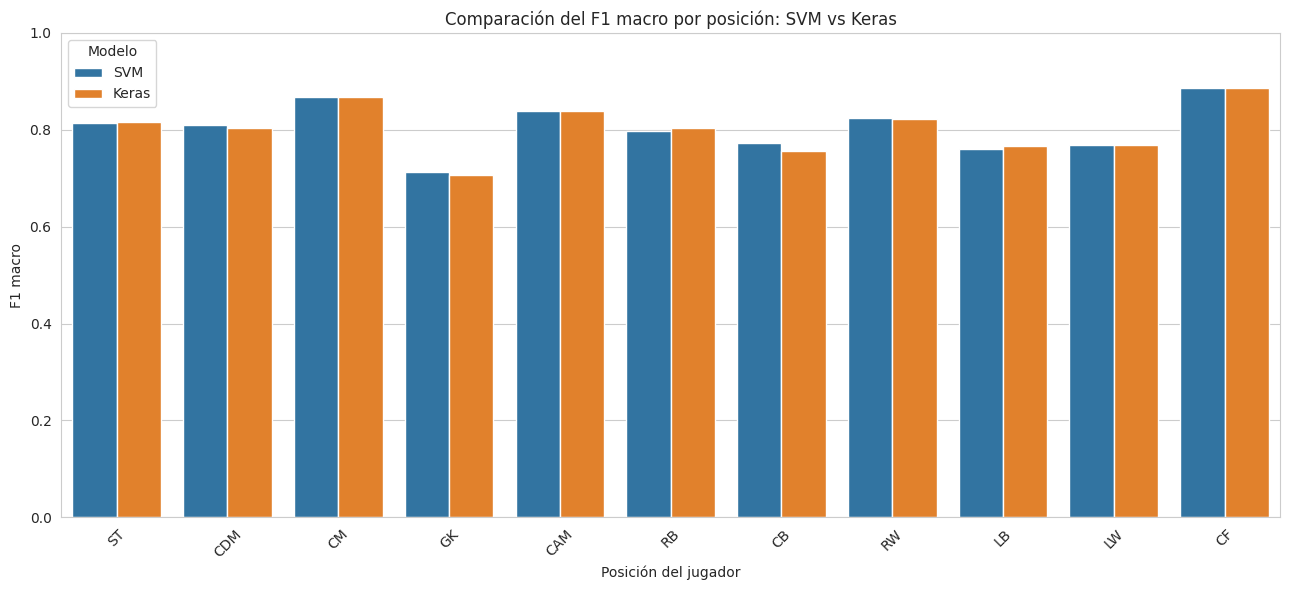

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

resultados_posicion_A = []

for posicion, grupo in datos_subgrupos_A.groupby("position"):

    for modelo in ["SVM", "Keras"]:

        y_real = grupo["clase_real"]
        y_pred = grupo[f"pred_{modelo}"]

        resultados_posicion_A.append({
            "Posición": posicion,
            "Modelo": modelo,
            "Registros": len(grupo),
            "F1 Macro": f1_score(
                y_real,
                y_pred,
                labels=["Bajo", "Medio", "Alto"],
                average="macro",
                zero_division=0
            ),
            "Tasa de error (%)": (
                grupo[f"error_{modelo}"].mean() * 100
            )
        })

tabla_posicion_A = pd.DataFrame(resultados_posicion_A)

# Ordenar las posiciones según cantidad de registros
orden_posiciones_A = (
    datos_subgrupos_A["position"]
    .value_counts()
    .index
    .tolist()
)

display(
    tabla_posicion_A.sort_values(
        ["Registros", "Modelo"],
        ascending=[False, True]
    ).round(3)
)

# Gráfica comparativa de F1 macro
plt.figure(figsize=(13, 6))

sns.barplot(
    data=tabla_posicion_A,
    x="Posición",
    y="F1 Macro",
    hue="Modelo",
    order=orden_posiciones_A
)

plt.title("Comparación del F1 macro por posición: SVM vs Keras")
plt.xlabel("Posición del jugador")
plt.ylabel("F1 macro")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend(title="Modelo")
plt.tight_layout()
plt.show()




Los resultados muestran diferencias en el rendimiento de SVM y Keras según la posición de los jugadores. **CF obtuvo el mayor F1 macro (0.887)** en ambos modelos, aunque con pocos registros (63), mientras que **GK presentó el menor (0.712)**. También se observaron dificultades en CB y LB.

En general, SVM superó a Keras en más posiciones. Estas diferencias podrían deberse a que las variables predictoras no representan igualmente bien el rendimiento de todas las posiciones, especialmente de porteros y defensores.

## Análisis del rendimiento por competición

Se evalúa el desempeño de SVM y Keras en las distintas competiciones del dataset, utilizando el F1 macro, la tasa de error y la cantidad de registros. El objetivo es identificar las competiciones donde los modelos presentan mayores dificultades.

,Competición,Modelo,Registros,F1 Macro,Tasa de error (%)
7,League,Keras,1455,0.815,18.557
6,League,SVM,1455,0.817,18.351
1,Champions League,Keras,417,0.819,18.705
0,Champions League,SVM,417,0.805,20.144
9,World Cup Qualifiers,Keras,326,0.773,23.006
8,World Cup Qualifiers,SVM,326,0.788,21.472
5,FIFA World Cup 2026,Keras,227,0.800,20.264
4,FIFA World Cup 2026,SVM,227,0.804,19.824
3,Domestic Cup,Keras,182,0.792,20.330
2,Domestic Cup,SVM,182,0.791,20.330


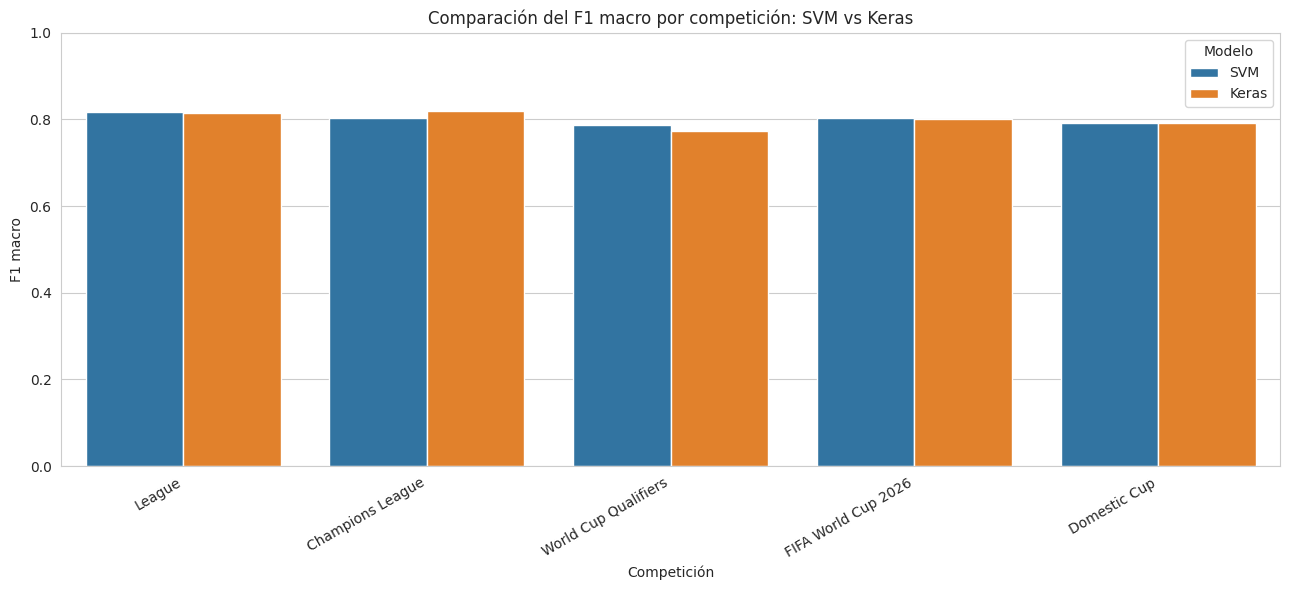

In [ ]:

# ANÁLISIS POR COMPETICIÓN

resultados_competicion_A = []

for competicion, grupo in datos_subgrupos_A.groupby("competition"):

    for modelo in ["SVM", "Keras"]:

        y_real = grupo["clase_real"]
        y_pred = grupo[f"pred_{modelo}"]

        resultados_competicion_A.append({
            "Competición": competicion,
            "Modelo": modelo,
            "Registros": len(grupo),
            "F1 Macro": f1_score(
                y_real,
                y_pred,
                labels=["Bajo", "Medio", "Alto"],
                average="macro",
                zero_division=0
            ),
            "Tasa de error (%)": (
                grupo[f"error_{modelo}"].mean() * 100
            )
        })

tabla_competicion_A = pd.DataFrame(resultados_competicion_A)

# Ordenar competiciones por cantidad de registros
orden_competiciones_A = (
    datos_subgrupos_A["competition"]
    .value_counts()
    .index
    .tolist()
)

# Mostrar tabla
display(
    tabla_competicion_A.sort_values(
        ["Registros", "Modelo"],
        ascending=[False, True]
    ).round(3)
)

# Gráfica comparativa
plt.figure(figsize=(13, 6))

sns.barplot(
    data=tabla_competicion_A,
    x="Competición",
    y="F1 Macro",
    hue="Modelo",
    order=orden_competiciones_A
)

plt.title("Comparación del F1 macro por competición: SVM vs Keras")
plt.xlabel("Competición")
plt.ylabel("F1 macro")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Modelo")
plt.tight_layout()
plt.show()


Los resultados muestran que SVM y Keras presentan un rendimiento similar en las distintas competiciones. **League obtuvo el mayor F1 macro con SVM (0.817)**, mientras que Keras destacó ligeramente en Champions League (0.812 frente a 0.805).

Las mayores dificultades se observaron en **World Cup Qualifiers y Domestic Cup**, donde ambos modelos presentaron menores valores de F1 macro y mayores tasas de error. En general, SVM superó a Keras en cuatro de las cinco competiciones, aunque las diferencias fueron pequeñas.

## Análisis del rendimiento por minutos jugados

Se analiza el comportamiento de SVM y Keras según el tiempo de participación de los jugadores, agrupando los registros en tres rangos. Se utilizan F1 macro, tasa de error y cantidad de registros para identificar posibles diferencias en el rendimiento predictivo.

,Rango de minutos,Modelo,Registros,F1 Macro,Tasa de error (%)
0,0-30 min,SVM,474,0.427,1.055
1,0-30 min,Keras,474,0.499,0.844
2,31-60 min,SVM,552,0.644,21.558
3,31-60 min,Keras,552,0.628,23.370
4,61+ min,SVM,1581,0.514,23.972
5,61+ min,Keras,1581,0.517,23.593


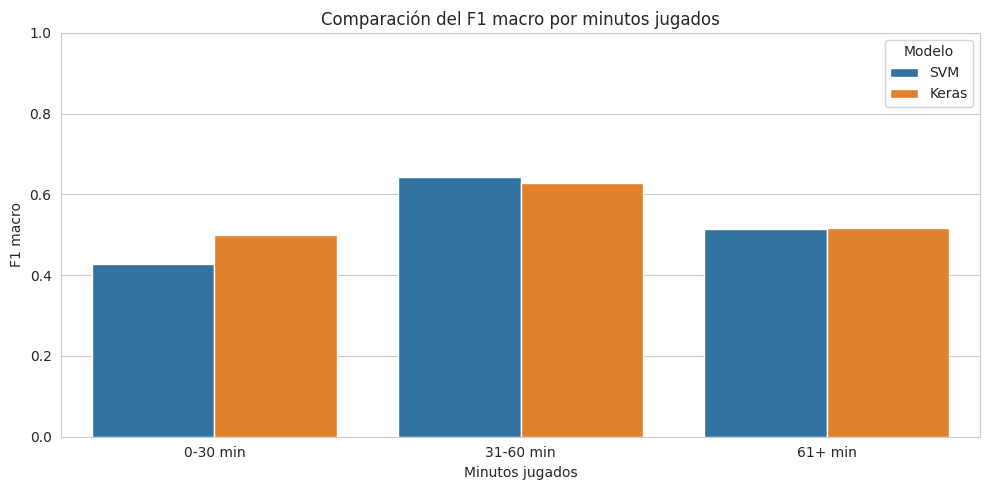

In [ ]:

# ANÁLISIS POR MINUTOS JUGADOS

# Crear rangos de minutos
datos_subgrupos_A["rango_minutos_A"] = pd.cut(
    datos_subgrupos_A["minutes_played"],
    bins=[-1, 30, 60, np.inf],
    labels=["0-30 min", "31-60 min", "61+ min"]
)

resultados_minutos_A = []

for rango, grupo in datos_subgrupos_A.groupby(
    "rango_minutos_A", observed=True
):
    for modelo in ["SVM", "Keras"]:

        y_real = grupo["clase_real"]
        y_pred = grupo[f"pred_{modelo}"]

        resultados_minutos_A.append({
            "Rango de minutos": str(rango),
            "Modelo": modelo,
            "Registros": len(grupo),
            "F1 Macro": f1_score(
                y_real,
                y_pred,
                labels=["Bajo", "Medio", "Alto"],
                average="macro",
                zero_division=0
            ),
            "Tasa de error (%)": (
                grupo[f"error_{modelo}"].mean() * 100
            )
        })

tabla_minutos_A = pd.DataFrame(resultados_minutos_A)

orden_minutos_A = ["0-30 min", "31-60 min", "61+ min"]

display(
    tabla_minutos_A.round(3)
)

# Gráfica comparativa
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tabla_minutos_A,
    x="Rango de minutos",
    y="F1 Macro",
    hue="Modelo",
    order=orden_minutos_A
)

plt.title("Comparación del F1 macro por minutos jugados")
plt.xlabel("Minutos jugados")
plt.ylabel("F1 macro")
plt.ylim(0, 1)
plt.legend(title="Modelo")
plt.tight_layout()
plt.show()



El rendimiento de SVM y Keras varía según los minutos jugados, principalmente debido al desbalance de clases en cada rango.

Entre 0 y 30 minutos, el 98.73% de los registros corresponde a rendimiento Bajo, lo que explica la baja tasa de error (1.06%) pese al F1 macro de 0.427. Entre 31 y 60 minutos, Keras obtuvo el mayor F1 macro (0.667), mientras que en 61 minutos o más ambos modelos presentaron resultados similares, cercanos a 0.51.

Estos resultados evidencian que la distribución de las categorías de rendimiento cambia considerablemente con los minutos jugados, lo que dificulta comparar directamente el F1 macro entre rangos.

#Ejemplos Reales

In [ ]:
df_err = df.iloc[test_idx].copy()
df_err["y_real"] = y_test.values
df_err["y_pred"] = modelos_candidatos["SVM (ajustado)"].predict(X_test)
df_err["error"] = df_err["y_real"] != df_err["y_pred"]
cols = ["player_name","position","minutes_played","distance_covered_km",
        "goals","assists","match_rating","y_real","y_pred"]

# Errores en la frontera (rating cercano a 5.6 o 6.8)
display(df_err[df_err.error & (df_err.match_rating.between(5.5,5.8) | df_err.match_rating.between(6.7,6.9))][cols].head(4))

# "Revulsivos": pocos minutos, marcan gol, y el modelo no los pone en Alto
rev = df_err[(df_err.minutes_played < 30) & (df_err.goals >= 1)]
print(f"Revulsivos: {len(rev)} partidos, error = {rev.error.mean()*100:.1f}%")
display(rev[rev.error][cols].head(4))

# Conteo de confusiones
display(pd.crosstab(df_err.y_real, df_err.y_pred))

,player_name,position,minutes_played,distance_covered_km,goals,assists,match_rating,y_real,y_pred
1,Achraf Hakimi,RB,63,10.31,0,0,6.9,Alto,Medio
14,Achraf Hakimi,RB,81,9.97,0,0,6.7,Medio,Alto
48,Achraf Hakimi,RB,85,14.50,0,0,6.8,Medio,Alto
349,Alessandro Bastoni,CB,90,7.96,0,0,6.8,Medio,Alto


Revulsivos: 17 partidos, error = 17.6%


,player_name,position,minutes_played,distance_covered_km,goals,assists,match_rating,y_real,y_pred
3663,Erling Braut Haaland,ST,28,4.10,1,0,5.8,Medio,Bajo
4309,Florian Wirtz,CAM,29,5.97,2,1,5.9,Medio,Alto
6515,Karim Benzema,ST,27,4.27,1,0,5.8,Medio,Bajo


y_pred,Alto,Bajo,Medio
y_real,,,
Bajo,0,783,85
Medio,175,73,718
Alto,603,0,170


## 18. Conclusiones Finales y Pasos Futuros

### Conclusiones del proyecto
1. **Superioridad frente a la línea base y similitud entre los mejores modelos:** Todos los algoritmos evaluados superaron ampliamente el clasificador aleatorio (`F1 macro = 0.330`). Los modelos de **SVM con kernel lineal (`F1 macro ≈ 0.822`)**, **Red Neuronal en Keras (`F1 macro ≈ 0.818 - 0.822`)** y **Random Forest (`F1 macro ≈ 0.815`)** lograron el mejor desempeño prácticamente empatados (diferencias menores a una desviación estándar entre folds), demostrando que la frontera de decisión entre las clases `Bajo`, `Medio` y `Alto` es predominantemente lineal/suave y que una mayor complejidad arquitectónica no genera ganancias adicionales con estas 6 variables.
2. **Importancia de la validación agrupada (`StratifiedGroupKFold`):** Separar los datos agrupando por `player_name` evitó la fuga de información (*data leakage*) por mediciones repetidas de los 229 jugadores, garantizando que las métricas reportadas reflejan la capacidad real de generalizar a jugadores nuevos en scouting. Asimismo, el uso de `max_depth = 8` en árboles y `EarlyStopping` + `Dropout` en Keras fue determinante para frenar el sobreajuste.
3. **Dependencia del tiempo de juego y límites de las variables actuales:** El análisis de `permutation_importance` y el experimento de ablación sin `minutes_played` confirmaron que la calificación del partido está fuertemente anclada al tiempo de participación en cancha. Cuando se elimina `minutes_played`, el modelo pierde cerca de 0.09–0.10 en F1 macro, pero logra sostenerse apoyándose en `distance_covered_km` como variable proxy.
4. **Origen de los errores:** Los fallos de clasificación no confunden actuaciones malas con sobresalientes (`Bajo` vs `Alto`), sino que se concentran en la frontera artificial de los terciles con la clase `Medio` y en posiciones defensivas/porteros (`GK`, `CB`) cuyo desempeño real no queda capturado únicamente por goles, asistencias o entradas.

---

### Pasos futuros (Recomendaciones de mejora)
1. **Incorporar la posición del jugador (`position`) y crear tasas por minuto (Feature Engineering):** Codificar la posición (o entrenar modelos segmentados por línea: atacantes, mediocampistas, defensas y porteros) e incluir variables normalizadas por tiempo jugado —como `km_por_minuto`, `goles_por_90min` y `pass_accuracy_pct` imputada— para evaluar justamente a los jugadores sustitutos y diferenciar las exigencias tácticas de cada rol.
2. **Reformular el problema como Regresión o Clasificación Ordinal:** Dado que la mayoría de los errores provienen de cortar artificialmente `match_rating` en los umbrales `5.6` y `6.8`, entrenar modelos de regresión directa (optimizando MAE/RMSE sobre `match_rating`) o clasificadores ordinales que penalicen más confundir `Bajo` con `Alto` que con `Medio`, aplicando los umbrales de negocio únicamente al final.
3. **Capturar la dinámica temporal e historial reciente del jugador:** Como cada jugador tiene múltiples partidos a lo largo de la temporada (`date`), construir variables de ventana móvil (por ejemplo, promedio de `match_rating` y minutos acumulados en los últimos 3 a 5 partidos) para capturar rachas de rendimiento y fatiga acumulada sin violar la partición temporal.
4. **Ampliar las métricas defensivas y de portería en la captura de datos:** Integrar variables como atajadas (*saves*), goles concedidos, intercepciones, duelos aéreos ganados y pases clave (*key passes*) para reducir la tasa de error en porteros y defensores centrales.

```markdown
# SECCIÓN 3: Aprendizaje No Supervisado (PCA y Clustering K-Means)
---
```

## 19. Reducción de dimensionalidad mediante PCA

Se aplica PCA a las seis variables numéricas del proyecto para estudiar si es posible reducir su dimensionalidad sin perder demasiada información.

Se utiliza únicamente el conjunto de entrenamiento para estudiar la varianza explicada. Posteriormente, se comparará el rendimiento del SVM original y el SVM con PCA utilizando la misma validación cruzada y las mismas métricas.

,Componentes,Varianza individual (%),Varianza acumulada (%)
0,1,34.81,34.81
1,2,21.11,55.92
2,3,16.05,71.97
3,4,13.47,85.44
4,5,11.00,96.44
5,6,3.56,100.00


Componentes necesarios para conservar 90%: 5


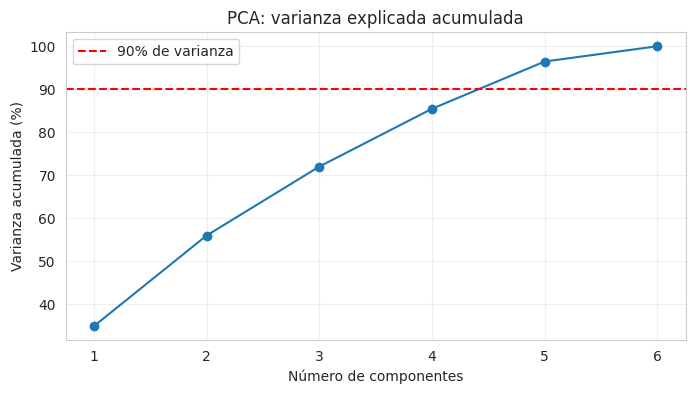

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Escalado ajustado únicamente con entrenamiento
escalador_ns = StandardScaler()
X_train_ns = escalador_ns.fit_transform(X_train)
X_test_ns = escalador_ns.transform(X_test)

# PCA exploratorio
pca_exploratorio = PCA()
pca_exploratorio.fit(X_train_ns)

varianza = pca_exploratorio.explained_variance_ratio_
acumulada = np.cumsum(varianza)

tabla_varianza = pd.DataFrame({
    "Componentes": np.arange(1, len(varianza) + 1),
    "Varianza individual (%)": varianza * 100,
    "Varianza acumulada (%)": acumulada * 100
})

display(tabla_varianza.round(2))

k_90 = np.searchsorted(acumulada, 0.90) + 1
print("Componentes necesarios para conservar 90%:", k_90)

plt.figure(figsize=(8, 4))
plt.plot(tabla_varianza["Componentes"],
         tabla_varianza["Varianza acumulada (%)"],
         marker="o")
plt.axhline(90, color="red", linestyle="--",
            label="90% de varianza")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada (%)")
plt.title("PCA: varianza explicada acumulada")
plt.xticks(range(1, len(varianza) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

El análisis de componentes principales (PCA) muestra que 5 componentes permiten conservar el 96.44% de la varianza total, superando el umbral establecido del 90%.

Con 4 componentes se conserva el 85.44%, por lo que no se alcanza el porcentaje deseado. En consecuencia, 5 componentes representan una alternativa para reducir la dimensionalidad, pasando de 6 variables originales a 5 componentes y perdiendo únicamente el 3.56% de la varianza.

Sin embargo, conservar una alta proporción de varianza no garantiza mejores predicciones. Por esta razón, es necesario comparar el rendimiento del modelo supervisado con y sin PCA.

### Comparar SVM original contra SVM con PCA

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

# Referencia: SVM ajustado con las 6 variables
referencia = metricas_cv(
    grid_svm.best_estimator_,
    "SVM original"
)

comparacion_pca = [{
    "Componentes": X_train.shape[1],
    "Varianza (%)": 100.0,
    "F1 macro CV": referencia["f1_macro_media"],
    "Balanced Accuracy CV": referencia["bal_acc_media"],
    "Accuracy CV": referencia["accuracy_media"]
}]

# Evaluar todas las alternativas con menos componentes
for k in range(1, X_train.shape[1]):

    modelo_pca = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=k)),
        ("model", clone(
            grid_svm.best_estimator_.named_steps["model"]
        ))
    ])

    resultado = cross_validate(
        modelo_pca,
        X_train, y_train,
        cv=cv,
        groups=groups_train,
        scoring=SCORING
    )

    comparacion_pca.append({
        "Componentes": k,
        "Varianza (%)": acumulada[k - 1] * 100,
        "F1 macro CV": resultado["test_f1_macro"].mean(),
        "Balanced Accuracy CV": resultado["test_bal_acc"].mean(),
        "Accuracy CV": resultado["test_accuracy"].mean()
    })

tabla_pca = pd.DataFrame(comparacion_pca)
display(tabla_pca.sort_values("Componentes").round(4))

# Elegir la mejor alternativa reducida según F1 macro CV
mejor_reducido = (
    tabla_pca[tabla_pca["Componentes"] < X_train.shape[1]]
    .sort_values("F1 macro CV", ascending=False)
    .iloc[0]
)

mejor_k = int(mejor_reducido["Componentes"])
print("Mejor número de componentes reducidos:", mejor_k)
print("Varianza conservada (%):",
      round(mejor_reducido["Varianza (%)"], 2))

# Entrenar con todo el conjunto de entrenamiento
svm_con_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=mejor_k)),
    ("model", clone(
        grid_svm.best_estimator_.named_steps["model"]
    ))
])
svm_con_pca.fit(X_train, y_train)

# Evaluación final: misma partición de prueba
resultados_pca_test = []

for nombre, modelo in [
    ("SVM original", grid_svm.best_estimator_),
    ("SVM con PCA", svm_con_pca)
]:
    pred = modelo.predict(X_test)

    resultados_pca_test.append({
        "Modelo": nombre,
        "F1 macro": f1_score(y_test, pred, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred)
    })

display(pd.DataFrame(resultados_pca_test).round(4))

,Componentes,Varianza (%),F1 macro CV,Balanced Accuracy CV,Accuracy CV
1,1,34.8056,0.7748,0.7731,0.7750
2,2,55.9197,0.7812,0.7793,0.7815
3,3,71.9709,0.7840,0.7819,0.7843
4,4,85.4386,0.7971,0.7950,0.7971
5,5,96.4424,0.7973,0.7952,0.7973
0,6,100.0000,0.8215,0.8212,0.8218


Mejor número de componentes reducidos: 5
Varianza conservada (%): 96.44


,Modelo,F1 macro,Balanced Accuracy,Accuracy
0,SVM original,0.8088,0.8085,0.8071
1,SVM con PCA,0.7828,0.7796,0.7806



Se comparó el modelo SVM original, utilizando las seis variables predictoras, con el mismo modelo aplicando reducción de dimensionalidad mediante PCA.

En validación cruzada, el **SVM original obtuvo un F1 macro de 0.8215**, mientras que la mejor configuración reducida, con 5 componentes y el 96.44% de la varianza conservada, alcanzó **0.7973**.

Al evaluar ambos modelos con los datos de prueba, el SVM original obtuvo un F1 macro de **0.8088**, frente a **0.7828** del SVM con PCA.

Estos resultados indican que, aunque PCA permite reducir la dimensionalidad conservando gran parte de la varianza, **no mejoró el rendimiento predictivo del SVM**. Por lo tanto, se considera más conveniente mantener las seis variables originales para esta tarea de clasificación.

## 20. Agrupamiento mediante K-Means

Se utiliza K-Means para identificar agrupamientos naturales entre los registros según las seis variables numéricas estandarizadas.

Se prueban diferentes cantidades de grupos y se comparan mediante el método del codo y el coeficiente de silueta. El número de grupos se selecciona utilizando los datos de entrenamiento, sin emplear las etiquetas reales.

,k,Inercia,Silueta
0,2,48502.9514,0.2492
1,3,39662.7690,0.2948
2,4,32203.3453,0.3327
3,5,26944.0344,0.3265
4,6,22794.7926,0.3405
5,7,21085.2115,0.3006
6,8,19942.6684,0.3048


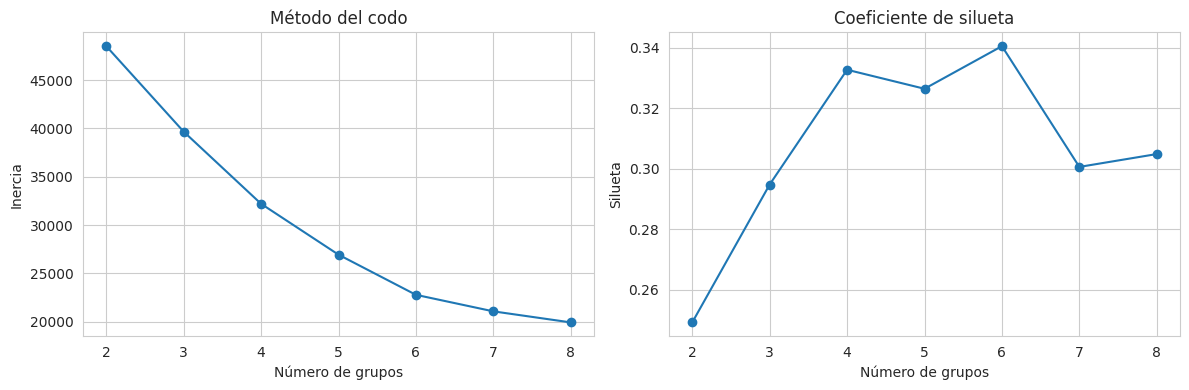

Cantidad de grupos seleccionada: 6


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados_kmeans = []

for k in range(2, 9):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    etiquetas = modelo.fit_predict(X_train_ns)

    silueta = silhouette_score(
        X_train_ns, etiquetas,
        sample_size=2000,
        random_state=42
    )

    resultados_kmeans.append({
        "k": k,
        "Inercia": modelo.inertia_,
        "Silueta": silueta
    })

tabla_kmeans = pd.DataFrame(resultados_kmeans)
display(tabla_kmeans.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(tabla_kmeans["k"],
             tabla_kmeans["Inercia"], marker="o")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de grupos")
axes[0].set_ylabel("Inercia")

axes[1].plot(tabla_kmeans["k"],
             tabla_kmeans["Silueta"], marker="o")
axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("Número de grupos")
axes[1].set_ylabel("Silueta")

plt.tight_layout()
plt.show()

# Selección según máxima silueta
mejor_num_grupos = int(
    tabla_kmeans.loc[tabla_kmeans["Silueta"].idxmax(), "k"]
)

print("Cantidad de grupos seleccionada:", mejor_num_grupos)

### Análisis de resultados de K-Means

Se evaluaron diferentes cantidades de grupos, desde 2 hasta 8, utilizando el método del codo y el coeficiente de silueta.

El método del codo mostró una disminución progresiva de la inercia, con reducciones menos pronunciadas a partir de aproximadamente 6 grupos.

Por su parte, **el mayor coeficiente de silueta se obtuvo con 6 grupos (0.3405)**, por lo que se seleccionó esta configuración para el análisis.

Sin embargo, este valor indica una separación limitada entre los grupos, lo que sugiere que los registros presentan cierto solapamiento en sus características.

En consecuencia, se utilizarán los 6 grupos para analizar sus características y estudiar su relación con las clases de rendimiento Bajo, Medio y Alto.

### Visualizar e interpretar los grupos

Cantidad de registros por grupo:


,count
Grupo,
0,210
1,776
2,376
3,705
4,278
5,262


Distribución de clases reales por grupo (%):


Clase real,Alto,Bajo,Medio
Grupo,,,
0,71.90,3.81,24.29
1,23.71,13.40,62.89
2,42.02,7.45,50.53
3,0.00,95.89,4.11
4,42.45,9.71,47.84
5,61.83,9.54,28.63


Promedios de las variables por grupo:


,minutes_played,distance_covered_km,goals,assists,shots_on_target,tackles
Grupo,,,,,,
0,73.50,7.53,1.20,0.05,0.39,0.62
1,74.78,8.10,0.00,0.00,0.00,0.83
2,77.26,8.26,0.02,0.02,0.07,4.13
3,23.97,2.59,0.02,0.00,0.07,0.35
4,76.37,8.08,0.11,0.01,1.45,0.60
5,70.72,7.90,0.15,1.11,0.41,0.82


Adjusted Rand Index: 0.2986


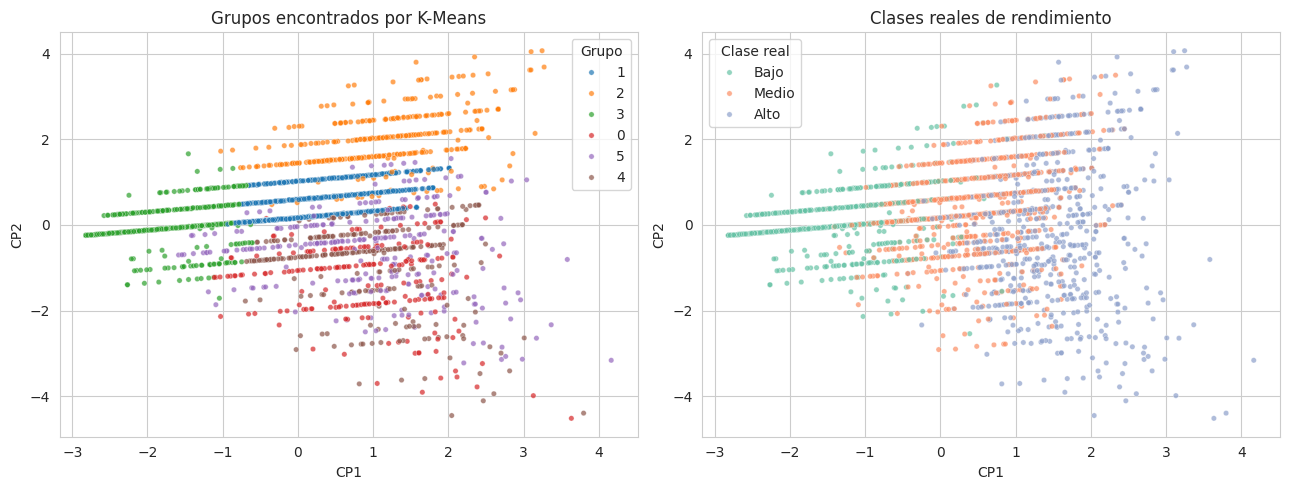

In [ ]:
from sklearn.metrics import adjusted_rand_score
import seaborn as sns

# Ajustar K-Means únicamente con entrenamiento
kmeans_final = KMeans(
    n_clusters=mejor_num_grupos,
    random_state=42,
    n_init=10
)
kmeans_final.fit(X_train_ns)

# Asignar grupos a los datos de prueba
grupos_test = kmeans_final.predict(X_test_ns)

datos_clusters = X_test.reset_index(drop=True).copy()
datos_clusters["Grupo"] = grupos_test
datos_clusters["Clase real"] = np.asarray(y_test)

print("Cantidad de registros por grupo:")
display(datos_clusters["Grupo"].value_counts().sort_index())

print("Distribución de clases reales por grupo (%):")
tabla_clases_grupos = pd.crosstab(
    datos_clusters["Grupo"],
    datos_clusters["Clase real"],
    normalize="index"
) * 100
display(tabla_clases_grupos.round(2))

print("Promedios de las variables por grupo:")
display(
    datos_clusters.groupby("Grupo")[top_vars]
    .mean().round(2)
)

print("Adjusted Rand Index:",
      round(adjusted_rand_score(y_test, grupos_test), 4))

# PCA de dos componentes solo para visualizar
pca_visual = PCA(n_components=2)
pca_visual.fit(X_train_ns)
coordenadas = pca_visual.transform(X_test_ns)

datos_visual = pd.DataFrame(
    coordenadas, columns=["CP1", "CP2"]
)
datos_visual["Grupo"] = grupos_test.astype(str)
datos_visual["Clase real"] = np.asarray(y_test).astype(str)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=datos_visual, x="CP1", y="CP2",
    hue="Grupo", palette="tab10",
    s=15, alpha=0.7, ax=axes[0]
)
axes[0].set_title("Grupos encontrados por K-Means")

sns.scatterplot(
    data=datos_visual, x="CP1", y="CP2",
    hue="Clase real", hue_order=ORDEN_CLASES,
    palette="Set2",
    s=15, alpha=0.7, ax=axes[1]
)
axes[1].set_title("Clases reales de rendimiento")

plt.tight_layout()
plt.show()

### Análisis e interpretación de los grupos encontrados

Mediante K-Means se identificaron **6 grupos de registros con características estadísticas similares**.

El grupo 0 presentó el mayor promedio de goles (1.20) y un predominio de rendimiento Alto (71.90%). Por su parte, el grupo 5 destacó por su promedio de asistencias (1.11), con un 61.83% de registros de rendimiento Alto.

En contraste, el grupo 3 presentó el menor promedio de minutos jugados (23.97) y una predominancia de rendimiento Bajo (95.89%). Los grupos 1, 2 y 4 presentaron mayor participación de la clase Medio, destacándose respectivamente por registros sin contribuciones ofensivas directas, mayor cantidad de entradas defensivas y mayor promedio de tiros a puerta.

Las visualizaciones mediante PCA permiten observar la distribución de los grupos y su relación con las clases reales, aunque existe solapamiento entre ellos.

Finalmente, el **Adjusted Rand Index de 0.2986** indica una coincidencia parcial entre los agrupamientos de K-Means y las clases Bajo, Medio y Alto.

En conclusión, K-Means permitió identificar perfiles estadísticos relacionados con diferentes niveles de rendimiento, aunque los grupos encontrados no representan directamente las categorías de clasificación supervisada.

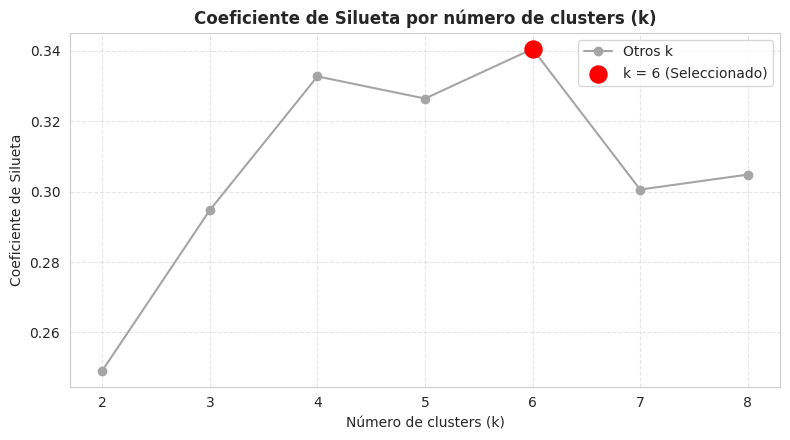

=== PROMEDIOS DE LAS VARIABLES POR GRUPO (TEST) ===


,minutes_played,distance_covered_km,goals,assists,shots_on_target,tackles
Grupo,,,,,,
0,73.50,7.53,1.20,0.05,0.39,0.62
1,74.78,8.10,0.00,0.00,0.00,0.83
2,77.26,8.26,0.02,0.02,0.07,4.13
3,23.97,2.59,0.02,0.00,0.07,0.35
4,76.37,8.08,0.11,0.01,1.45,0.60
5,70.72,7.90,0.15,1.11,0.41,0.82


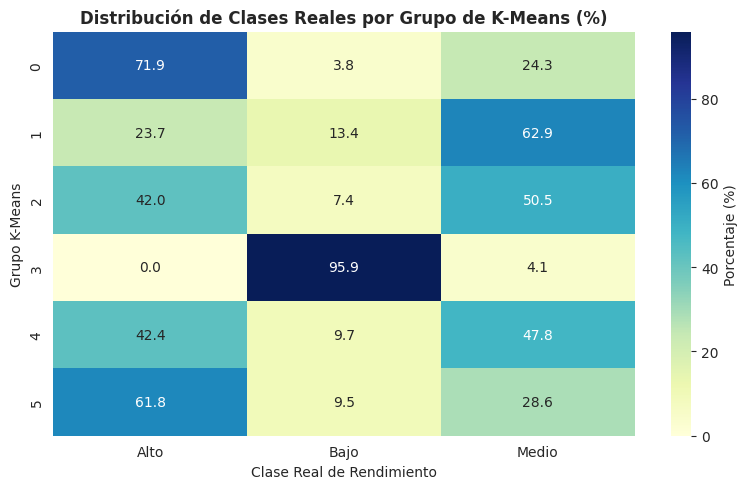

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Gráfico de silueta contra k con k=6 resaltado
plt.figure(figsize=(8, 4.5))
plt.plot(tabla_kmeans["k"], tabla_kmeans["Silueta"], marker="o", color="#A5A5A5", linestyle="-", label="Otros k")
plt.scatter(6, tabla_kmeans.loc[tabla_kmeans["k"] == 6, "Silueta"].values[0], color="red", s=150, zorder=5, label="k = 6 (Seleccionado)")
plt.title("Coeficiente de Silueta por número de clusters (k)", fontsize=12, fontweight="bold")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente de Silueta")
plt.xticks(tabla_kmeans["k"])
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Tabla de medias por grupo en el conjunto de prueba
print("=== PROMEDIOS DE LAS VARIABLES POR GRUPO (TEST) ===")
promedios_grupos = datos_clusters.groupby("Grupo")[top_vars].mean()
display(promedios_grupos.round(2))

# 3. Heatmap de grupos contra Bajo, Medio y Alto (porcentajes de distribución)
plt.figure(figsize=(8, 5))
sns.heatmap(tabla_clases_grupos, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Porcentaje (%)"})
plt.title("Distribución de Clases Reales por Grupo de K-Means (%)", fontsize=12, fontweight="bold")
plt.xlabel("Clase Real de Rendimiento")
plt.ylabel("Grupo K-Means")
plt.tight_layout()
plt.show()

## 21. Conclusiones finales del proyecto

### Conclusiones

1. **Aprendizaje supervisado:** Se compararon cinco modelos para clasificar el rendimiento de los jugadores en Bajo, Medio y Alto. SVM obtuvo el mejor F1 macro en validación cruzada (0.8215), seguido de Keras (0.8201). Esto demuestra que modelos de diferente complejidad pueden alcanzar resultados similares.

2. **Importancia del análisis exploratorio (EDA):** El EDA permitió identificar las variables más relacionadas con el rendimiento, detectar valores faltantes y seleccionar seis características predictoras. También permitió identificar la fuerte relación entre los minutos jugados y la calificación del partido.

3. **Reducción de dimensionalidad mediante PCA:** Se encontró que cinco componentes conservan el 96.44% de la varianza de las seis variables originales. Sin embargo, al comparar el SVM original con el SVM reducido, el F1 macro en prueba disminuyó de 0.8088 a 0.7828. Por tanto, PCA permitió reducir la dimensionalidad, pero no mejoró el rendimiento predictivo en este experimento.

4. **Aprendizaje no supervisado mediante K-Means:** Se identificaron seis grupos de registros con características estadísticas diferentes, seleccionados mediante el coeficiente de silueta (0.3405). Algunos grupos estuvieron asociados principalmente con rendimientos altos y otros con rendimientos bajos, demostrando que es posible descubrir patrones sin utilizar las etiquetas de clasificación.

5. **Relación entre agrupamientos y clases:** El Adjusted Rand Index de 0.2986 indica una coincidencia parcial entre los grupos de K-Means y las clases reales. Esto demuestra que los agrupamientos no representan necesariamente las mismas categorías utilizadas en clasificación supervisada.

6. **Fortalezas y limitaciones:** El proyecto permitió aplicar conceptos del curso como EDA, clasificación supervisada, validación cruzada, optimización de hiperparámetros, PCA y agrupamiento. Sin embargo, el rendimiento depende de las variables disponibles y existen dificultades para representar adecuadamente algunas posiciones y distinguir categorías de rendimiento cercanas.

### Recomendaciones de mejora

- Incorporar estadísticas específicas por posición, especialmente para porteros y defensores.
- Evaluar nuevas variables y técnicas de reducción de dimensionalidad para comprobar si mejoran la clasificación.
- Realizar la selección de variables y la imputación dentro del proceso de entrenamiento y validación, evitando posibles fugas de información.
- Explorar otros métodos de agrupamiento para comparar la calidad de los grupos encontrados.

### Conclusión general

El aprendizaje supervisado permitió predecir las categorías de rendimiento, mientras que el aprendizaje no supervisado permitió explorar patrones presentes en los datos. PCA demostró que reducir la dimensionalidad no garantiza mejores predicciones, y K-Means permitió identificar perfiles estadísticos sin utilizar las clases reales.

En conjunto, el proyecto evidencia la importancia de seleccionar adecuadamente las variables, evaluar los modelos y comprender las limitaciones de cada técnica.